In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [1]:
# Basic libraries
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

# Model building
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB

# Model evaluation and tuning
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Saving models
import joblib

# Other utilities
from pathlib import Path
import json
import re
import warnings

# Configuration
RANDOM_STATE = 42
TARGET = "team_label"

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 100)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Define dataset folder
DATA_DIR = Path("data")

# Load datasets
train_df = pd.read_csv(rf"C:\Users\shiva kumar\Downloads\08758214-ae0c-4fb9-bd84-85d256f7b48f-train.csv")
test_df = pd.read_csv(rf"C:\Users\shiva kumar\Downloads\a85b92d4-2e95-4877-9628-629f67ec3dcf-test_unlabelled.csv")
teams_df = pd.read_csv(rf"C:\Users\shiva kumar\Downloads\697fb5c8-4f7c-4152-9504-1065b9b4fa60-teams.csv")
resolution_df = pd.read_csv(rf"C:\Users\shiva kumar\Downloads\3b74ba57-8e89-48c7-becc-f229c8ddbdb4-resolution_log.csv")
sample_submission_df = pd.read_csv(rf"C:\Users\shiva kumar\Downloads\a9235996-dae0-4069-bfe2-dd3f6cd2f08d-sample_submission.csv")

In [3]:
train_df.head()

,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source,team_label
0,SR500000,2025-04-01 00:31,whatsapp,Robot Vacuum,shield,sir how to clean robot vacuum reg no SR75294,legacy_zoho,Product Advice
1,SR500001,2025-04-01 01:27,chat,Water Purifier,out_of_warranty,"hello team, emi conversion not done for purifi...",legacy_zoho,Billing
2,SR500002,2025-04-01 03:26,whatsapp,Water Purifier,in_warranty,claim status for purifier under warranty paid ...,legacy_zoho,Billing
3,SR500003,2025-04-01 04:50,chat,Robot Vacuum,in_warranty,sir spare blade set for fan available? asap,legacy_zoho,Consumables
4,SR500004,2025-04-01 06:39,ivr,Air Fryer,out_of_warranty,"hi, display of air fryer gone blank thanks",legacy_zoho,Repairs


In [4]:
print(test_df.head())
print(teams_df.head())
print(resolution_df.head())
print(sample_submission_df.head())

  request_id    created_at_ist channel  product_family warranty_status  \
0   SR510822  2026-07-01 00:31    chat       Air Fryer     in_warranty   
1   SR510823  2026-07-01 02:01    chat       Air Fryer          shield   
2   SR510824  2026-07-01 03:07     ivr  Water Purifier     in_warranty   
3   SR510825  2026-07-01 04:56   email    Robot Vacuum     in_warranty   
4   SR510826  2026-07-01 05:13    chat   Mixer Grinder     in_warranty   

                                        request_text source  
0      display of air fryer gone blank pls call back    crm  
1  good morning, want AMC filter kit for air frye...    crm  
2  sir water purifier leaking water from bottom p...    crm  
3  hi, installer did not turn up for cooktop i pa...    crm  
4  good morning, installation slot for mixer grin...    crm  
                    team                                renamed_to  \
0          Installations        Installs & Demo (from 15 Jan 2026)   
1                Repairs                   

In [5]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)
print("Teams Dataset Shape:", teams_df.shape)
print("Resolution Log Shape:", resolution_df.shape)
print("Sample Submission Shape:", sample_submission_df.shape)

Training Dataset Shape: (10822, 8)
Testing Dataset Shape: (2178, 7)
Teams Dataset Shape: (7, 3)
Resolution Log Shape: (10822, 5)
Sample Submission Shape: (2178, 2)


In [6]:
print("TRAIN DATASET")
display(train_df.head())

print("TEST DATASET")
display(test_df.head())

print("TEAMS DATASET")
display(teams_df.head())

print("RESOLUTION LOG DATASET")
display(resolution_df.head())

print("SAMPLE SUBMISSION DATASET")
display(sample_submission_df.head())

TRAIN DATASET


,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source,team_label
0,SR500000,2025-04-01 00:31,whatsapp,Robot Vacuum,shield,sir how to clean robot vacuum reg no SR75294,legacy_zoho,Product Advice
1,SR500001,2025-04-01 01:27,chat,Water Purifier,out_of_warranty,"hello team, emi conversion not done for purifi...",legacy_zoho,Billing
2,SR500002,2025-04-01 03:26,whatsapp,Water Purifier,in_warranty,claim status for purifier under warranty paid ...,legacy_zoho,Billing
3,SR500003,2025-04-01 04:50,chat,Robot Vacuum,in_warranty,sir spare blade set for fan available? asap,legacy_zoho,Consumables
4,SR500004,2025-04-01 06:39,ivr,Air Fryer,out_of_warranty,"hi, display of air fryer gone blank thanks",legacy_zoho,Repairs


TEST DATASET


,request_id,created_at_ist,channel,product_family,warranty_status,request_text,source
0,SR510822,2026-07-01 00:31,chat,Air Fryer,in_warranty,display of air fryer gone blank pls call back,crm
1,SR510823,2026-07-01 02:01,chat,Air Fryer,shield,"good morning, want AMC filter kit for air frye...",crm
2,SR510824,2026-07-01 03:07,ivr,Water Purifier,in_warranty,sir water purifier leaking water from bottom p...,crm
3,SR510825,2026-07-01 04:56,email,Robot Vacuum,in_warranty,"hi, installer did not turn up for cooktop i pa...",crm
4,SR510826,2026-07-01 05:13,chat,Mixer Grinder,in_warranty,"good morning, installation slot for mixer grin...",crm


TEAMS DATASET


,team,renamed_to,handles
0,Installations,Installs & Demo (from 15 Jan 2026),"New-product installation, demo and wall-mounti..."
1,Repairs,NaN,"Product faults, breakdowns, error codes, noise..."
2,Consumables,Filters & Consumables (from 15 Jan 2026),"Filters, candles, membranes, jars, brushes, bl..."
3,Billing,NaN,"Invoices, GST, double charges, refunds of paym..."
4,Returns & Replacement,NaN,"Damaged, wrong or incomplete deliveries; retur..."


RESOLUTION LOG DATASET


,request_id,first_team,final_team,transfers,resolved_at
0,SR500000,Product Advice,Product Advice,0,2025-04-01 11:04
1,SR500001,Billing,Billing,0,2025-03-31 22:41
2,SR500002,Billing,Warranty Claims,1,2025-04-01 13:26
3,SR500003,Consumables,Consumables,0,2025-04-01 11:07
4,SR500004,Repairs,Repairs,1,2025-04-01 09:18


SAMPLE SUBMISSION DATASET


,request_id,team
0,SR510822,Repairs
1,SR510823,Repairs
2,SR510824,Repairs
3,SR510825,Repairs
4,SR510826,Repairs


In [7]:
print("Train Columns:")
print(train_df.columns.tolist())

print("\nTest Columns:")
print(test_df.columns.tolist())

print("\nTeams Columns:")
print(teams_df.columns.tolist())

print("\nResolution Log Columns:")
print(resolution_df.columns.tolist())

Train Columns:
['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source', 'team_label']

Test Columns:
['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source']

Teams Columns:
['team', 'renamed_to', 'handles']

Resolution Log Columns:
['request_id', 'first_team', 'final_team', 'transfers', 'resolved_at']


In [8]:
print("TRAIN DATASET INFORMATION")
train_df.info()

print("\nTEST DATASET INFORMATION")
test_df.info()

print("\nTEAMS DATASET INFORMATION")
teams_df.info()

print("\nRESOLUTION DATASET INFORMATION")
resolution_df.info()

TRAIN DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10822 entries, 0 to 10821
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   request_id       10822 non-null  object
 1   created_at_ist   10822 non-null  object
 2   channel          10822 non-null  object
 3   product_family   10822 non-null  object
 4   warranty_status  10822 non-null  object
 5   request_text     10822 non-null  object
 6   source           10822 non-null  object
 7   team_label       10822 non-null  object
dtypes: object(8)
memory usage: 676.5+ KB

TEST DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2178 entries, 0 to 2177
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   request_id       2178 non-null   object
 1   created_at_ist   2178 non-null   object
 2   channel          2178 non-null   object
 3   product_fami

In [9]:
print("Training Dataset Duplicates:", train_df.duplicated().sum())
print("Testing Dataset Duplicates:", test_df.duplicated().sum())
print("Teams Dataset Duplicates:", teams_df.duplicated().sum())
print("Resolution Dataset Duplicates:", resolution_df.duplicated().sum())

Training Dataset Duplicates: 0
Testing Dataset Duplicates: 0
Teams Dataset Duplicates: 0
Resolution Dataset Duplicates: 0


In [10]:
print("Training Dataset Statistical Summary:")
display(train_df.describe(include="all").T)

print("Testing Dataset Statistical Summary:")
display(test_df.describe(include="all").T)

Training Dataset Statistical Summary:


,count,unique,top,freq
request_id,10822,10822,SR510821,1
created_at_ist,10822,10741,2025-07-16 11:36,2
channel,10822,4,chat,3337
product_family,10822,7,Water Purifier,2190
warranty_status,10822,3,in_warranty,5887
request_text,10822,10159,"hi, is room heater safe for kids",4
source,10822,2,crm,6502
team_label,10822,9,Repairs,3129


Testing Dataset Statistical Summary:


,count,unique,top,freq
request_id,2178,2178,SR512999,1
created_at_ist,2178,2160,2026-07-10 02:46,3
channel,2178,4,whatsapp,661
product_family,2178,7,Water Purifier,455
warranty_status,2178,3,in_warranty,1192
request_text,2178,2145,urgent: installation slot for water purifier n...,3
source,2178,1,crm,2178


In [11]:
categorical_columns = train_df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Unique Values:", train_df[column].nunique())
    print(train_df[column].value_counts(dropna=False).head(10))


Column: request_id
Unique Values: 10822
request_id
SR510821    1
SR500000    1
SR500001    1
SR500002    1
SR500003    1
SR500004    1
SR510805    1
SR510804    1
SR510803    1
SR510802    1
Name: count, dtype: int64

Column: created_at_ist
Unique Values: 10741
created_at_ist
2025-07-16 11:36    2
2025-10-16 23:48    2
2025-05-22 14:14    2
2025-11-14 19:54    2
2025-04-04 08:45    2
2025-06-26 08:41    2
2025-11-16 08:12    2
2025-08-18 12:16    2
2025-04-17 12:20    2
2025-06-28 05:40    2
Name: count, dtype: int64

Column: channel
Unique Values: 4
channel
chat        3337
whatsapp    3230
ivr         3141
email       1114
Name: count, dtype: int64

Column: product_family
Unique Values: 7
product_family
Water Purifier       2190
Air Fryer            1927
Mixer Grinder        1611
Induction Cooktop    1470
Room Heater          1294
Ceiling Fan          1290
Robot Vacuum         1040
Name: count, dtype: int64

Column: warranty_status
Unique Values: 3
warranty_status
in_warranty       

In [12]:
print("Available Training Columns:")
print(train_df.columns.tolist())

Available Training Columns:
['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source', 'team_label']


In [13]:
display(train_df["team_label"].value_counts())

team_label
Repairs                  3129
Billing                  1656
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Consumables               927
Installations             745
Filters & Consumables     531
Installs & Demo           440
Name: count, dtype: int64

In [14]:
print("Training Request ID Duplicates:",
      train_df["request_id"].duplicated().sum())

print("Testing Request ID Duplicates:",
      test_df["request_id"].duplicated().sum())

print("Training Total Records:", len(train_df))
print("Training Unique Request IDs:", train_df["request_id"].nunique())

Training Request ID Duplicates: 0
Testing Request ID Duplicates: 0
Training Total Records: 10822
Training Unique Request IDs: 10822


In [15]:
# Create working copies
train_clean = train_df.copy()
test_clean = test_df.copy()

# Preserve original target labels for reference
train_clean["team_label_original"] = train_clean["team_label"].copy()

print("Working datasets created successfully!")

Working datasets created successfully!


In [16]:
# Standardize team names
team_mapping = {
    "Installations": "Installs & Demo",
    "Consumables": "Filters & Consumables"
}

train_clean["team_label"] = (
    train_clean["team_label"]
    .replace(team_mapping)
)

print("Updated Team Distribution:")
display(train_clean["team_label"].value_counts())

Updated Team Distribution:


team_label
Repairs                  3129
Billing                  1656
Filters & Consumables    1458
Installs & Demo          1185
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Name: count, dtype: int64

In [17]:
# Convert timestamp columns
train_clean["created_at_ist"] = pd.to_datetime(
    train_clean["created_at_ist"],
    errors="coerce"
)

test_clean["created_at_ist"] = pd.to_datetime(
    test_clean["created_at_ist"],
    errors="coerce"
)

print("Training Timestamp Data Type:",
      train_clean["created_at_ist"].dtype)

print("Testing Timestamp Data Type:",
      test_clean["created_at_ist"].dtype)

Training Timestamp Data Type: datetime64[ns]
Testing Timestamp Data Type: datetime64[ns]


In [18]:
text_columns = ["request_text"]

for column in text_columns:

    train_clean[column] = (
        train_clean[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

    test_clean[column] = (
        test_clean[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print("Text cleaning completed!")

Text cleaning completed!


In [19]:
categorical_columns = [
    "channel",
    "product_family",
    "warranty_status",
    "source"
]

for column in categorical_columns:

    train_clean[column] = (
        train_clean[column]
        .fillna("unknown")
        .astype(str)
        .str.strip()
    )

    test_clean[column] = (
        test_clean[column]
        .fillna("unknown")
        .astype(str)
        .str.strip()
    )

print("Categorical cleaning completed!")

Categorical cleaning completed!


In [20]:
print("Missing Target Values:",
      train_clean["team_label"].isnull().sum())

# Remove rows only when target label is missing
train_clean = train_clean.dropna(
    subset=["team_label"]
).copy()

print("Training Dataset Shape After Cleaning:",
      train_clean.shape)

Missing Target Values: 0
Training Dataset Shape After Cleaning: (10822, 9)


In [21]:
print("TRAINING DATASET")
display(train_clean.isnull().sum().to_frame("Missing Values"))

print("\nTESTING DATASET")
display(test_clean.isnull().sum().to_frame("Missing Values"))

print("\nFinal Training Shape:", train_clean.shape)
print("Final Testing Shape:", test_clean.shape)

print("\nFinal Target Distribution:")
display(train_clean["team_label"].value_counts())

TRAINING DATASET


,Missing Values
request_id,0
created_at_ist,0
channel,0
product_family,0
warranty_status,0
request_text,0
source,0
team_label,0
team_label_original,0



TESTING DATASET


,Missing Values
request_id,0
created_at_ist,0
channel,0
product_family,0
warranty_status,0
request_text,0
source,0



Final Training Shape: (10822, 9)
Final Testing Shape: (2178, 7)

Final Target Distribution:


team_label
Repairs                  3129
Billing                  1656
Filters & Consumables    1458
Installs & Demo          1185
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Name: count, dtype: int64

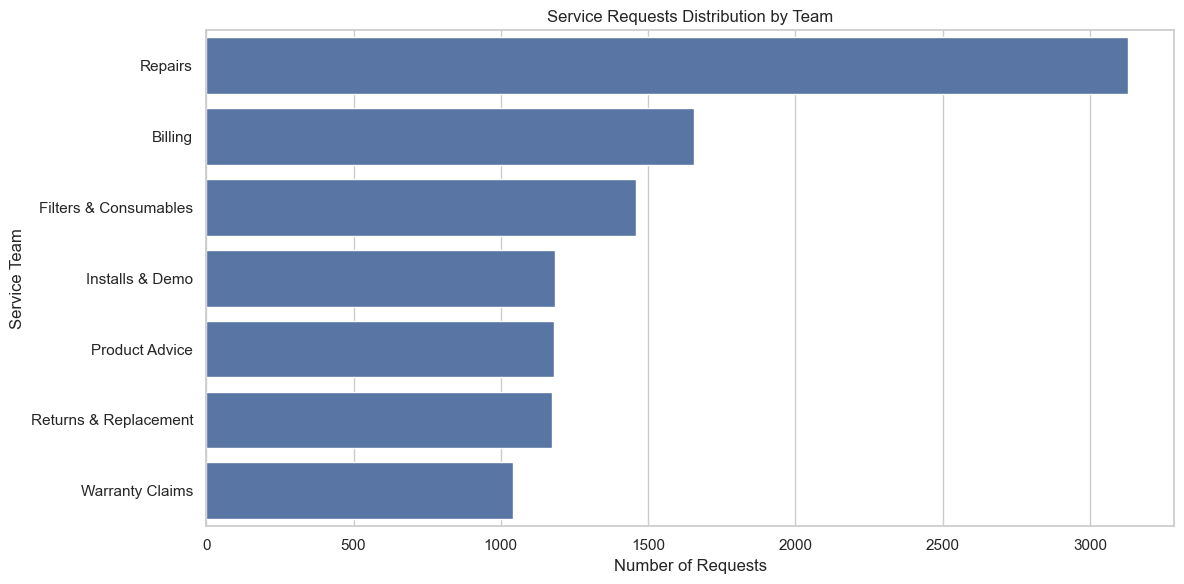

In [22]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_clean,
    y="team_label",
    order=train_clean["team_label"].value_counts().index
)

plt.title("Service Requests Distribution by Team")
plt.xlabel("Number of Requests")
plt.ylabel("Service Team")
plt.tight_layout()
plt.show()

In [23]:
team_distribution = (
    train_clean["team_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

team_distribution.columns = ["Team", "Percentage"]

display(team_distribution)

,Team,Percentage
0,Repairs,28.91
1,Billing,15.30
2,Filters & Consumables,13.47
3,Installs & Demo,10.95
4,Product Advice,10.90
5,Returns & Replacement,10.85
6,Warranty Claims,9.61


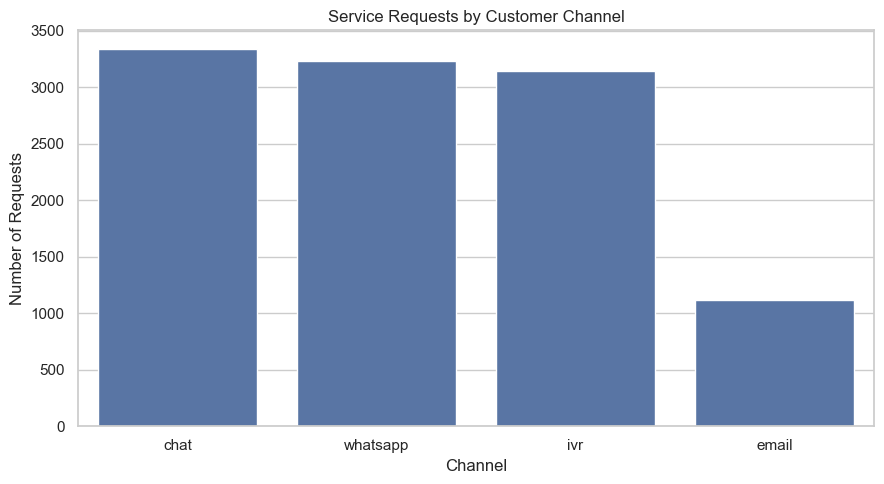

In [24]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_clean,
    x="channel",
    order=train_clean["channel"].value_counts().index
)

plt.title("Service Requests by Customer Channel")
plt.xlabel("Channel")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

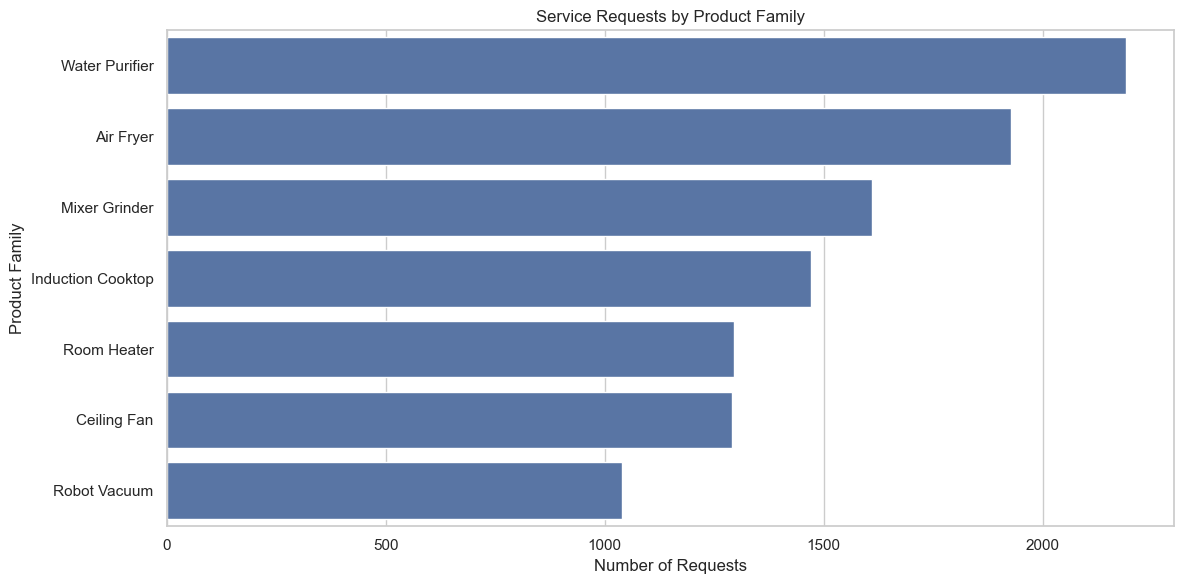

In [25]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_clean,
    y="product_family",
    order=train_clean["product_family"].value_counts().index
)

plt.title("Service Requests by Product Family")
plt.xlabel("Number of Requests")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()

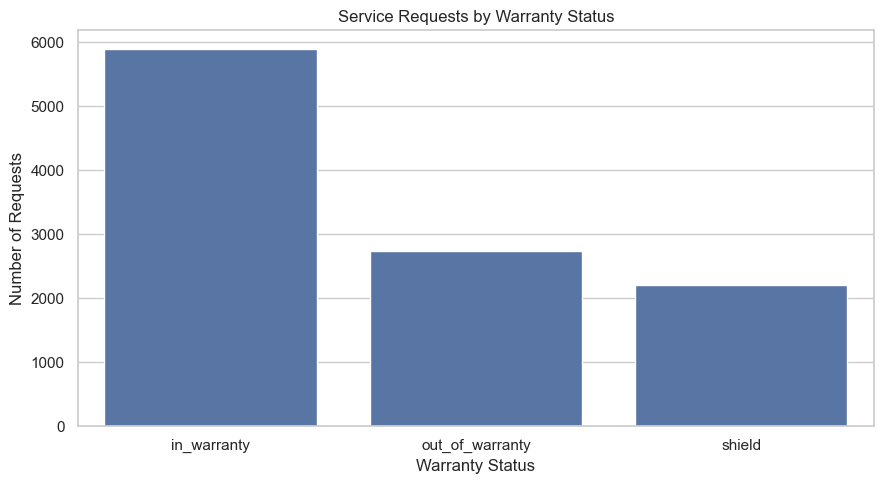

In [26]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_clean,
    x="warranty_status",
    order=train_clean["warranty_status"].value_counts().index
)

plt.title("Service Requests by Warranty Status")
plt.xlabel("Warranty Status")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

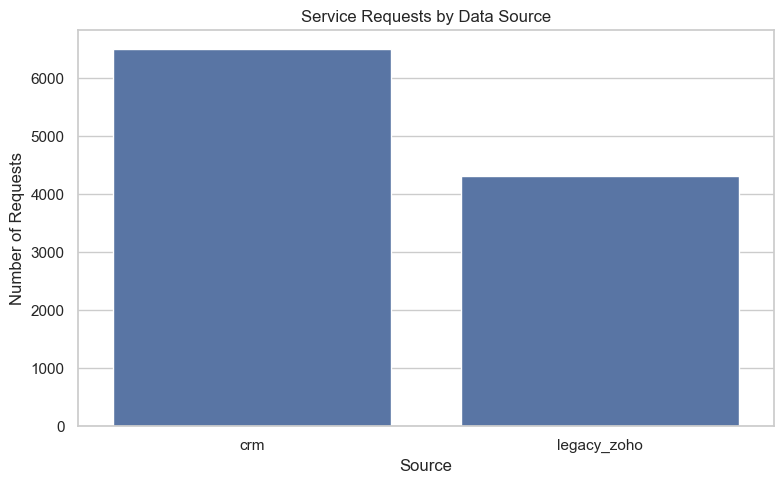

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_clean,
    x="source",
    order=train_clean["source"].value_counts().index
)

plt.title("Service Requests by Data Source")
plt.xlabel("Source")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

team_label,Billing,Filters & Consumables,Installs & Demo,Product Advice,Repairs,Returns & Replacement,Warranty Claims
channel,,,,,,,
chat,492,449,360,365,955,369,347
email,179,163,117,124,293,119,119
ivr,501,433,342,356,910,326,273
whatsapp,484,413,366,335,971,360,301


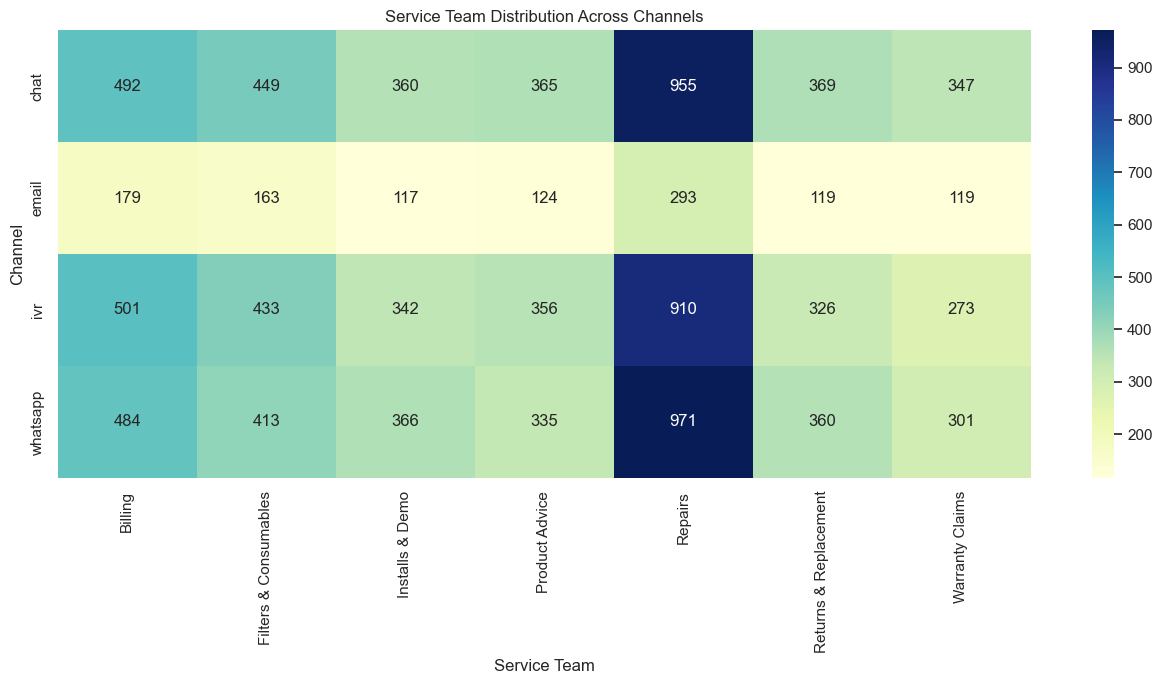

In [28]:
channel_team = pd.crosstab(
    train_clean["channel"],
    train_clean["team_label"]
)

display(channel_team)

plt.figure(figsize=(13, 7))

sns.heatmap(
    channel_team,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Service Team Distribution Across Channels")
plt.xlabel("Service Team")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

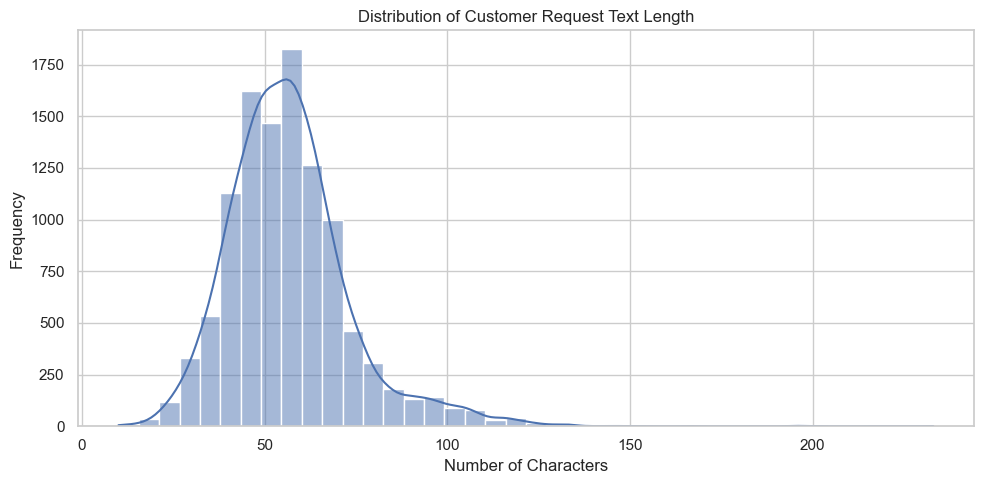

Average Text Length: 56.58556643873591
Maximum Text Length: 233


In [29]:
train_clean["text_length"] = (
    train_clean["request_text"].str.len()
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_clean,
    x="text_length",
    bins=40,
    kde=True
)

plt.title("Distribution of Customer Request Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Average Text Length:",
      train_clean["text_length"].mean())

print("Maximum Text Length:",
      train_clean["text_length"].max())

team_label,Billing,Filters & Consumables,Installs & Demo,Product Advice,Repairs,Returns & Replacement,Warranty Claims
warranty_status,,,,,,,
in_warranty,14.76,13.44,11.28,11.33,28.95,10.45,9.80
out_of_warranty,16.90,13.23,10.30,10.23,28.70,11.22,9.42
shield,14.77,13.86,10.87,10.60,29.09,11.46,9.33


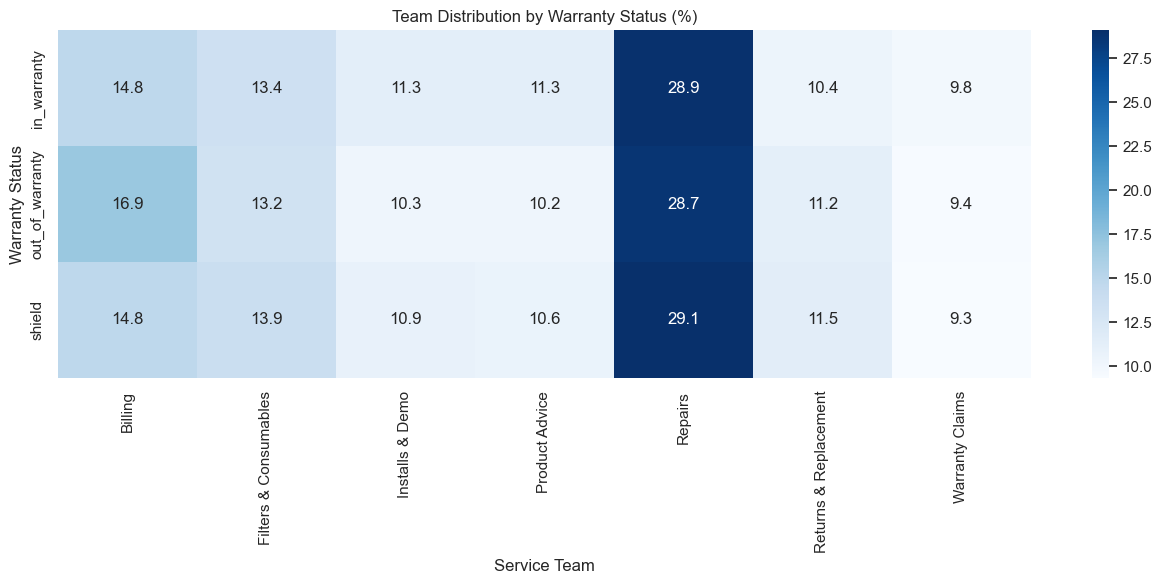

In [31]:
warranty_team = pd.crosstab(
    train_clean["warranty_status"],
    train_clean["team_label"],
    normalize="index"
) * 100

display(warranty_team.round(2))

plt.figure(figsize=(13, 6))

sns.heatmap(
    warranty_team,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Team Distribution by Warranty Status (%)")
plt.xlabel("Service Team")
plt.ylabel("Warranty Status")
plt.tight_layout()
plt.show()

In [32]:
print("Earliest Request Date:",
      train_clean["created_at_ist"].min())

print("Latest Request Date:",
      train_clean["created_at_ist"].max())

print("\nDate Range:")
print(
    train_clean["created_at_ist"].max()
    - train_clean["created_at_ist"].min()
)

Earliest Request Date: 2025-04-01 00:31:00
Latest Request Date: 2026-06-30 23:33:00

Date Range:
455 days 23:02:00


In [33]:
# Extract hour
train_clean["request_hour"] = (
    train_clean["created_at_ist"].dt.hour
)

test_clean["request_hour"] = (
    test_clean["created_at_ist"].dt.hour
)

# Extract day of week
train_clean["request_day"] = (
    train_clean["created_at_ist"].dt.dayofweek
)

test_clean["request_day"] = (
    test_clean["created_at_ist"].dt.dayofweek
)

# Extract month
train_clean["request_month"] = (
    train_clean["created_at_ist"].dt.month
)

test_clean["request_month"] = (
    test_clean["created_at_ist"].dt.month
)

# Extract day of month
train_clean["request_day_of_month"] = (
    train_clean["created_at_ist"].dt.day
)

test_clean["request_day_of_month"] = (
    test_clean["created_at_ist"].dt.day
)

# Weekend indicator
train_clean["is_weekend"] = (
    train_clean["request_day"] >= 5
).astype(int)

test_clean["is_weekend"] = (
    test_clean["request_day"] >= 5
).astype(int)

print("Date-Time Feature Engineering Completed!")

Date-Time Feature Engineering Completed!


In [34]:
def categorize_time(hour):

    if 5 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"


train_clean["time_period"] = (
    train_clean["request_hour"].apply(categorize_time)
)

test_clean["time_period"] = (
    test_clean["request_hour"].apply(categorize_time)
)

print("Time Period Distribution:")
display(train_clean["time_period"].value_counts())

Time Period Distribution:


time_period
Night        3564
Morning      3225
Afternoon    2216
Evening      1817
Name: count, dtype: int64

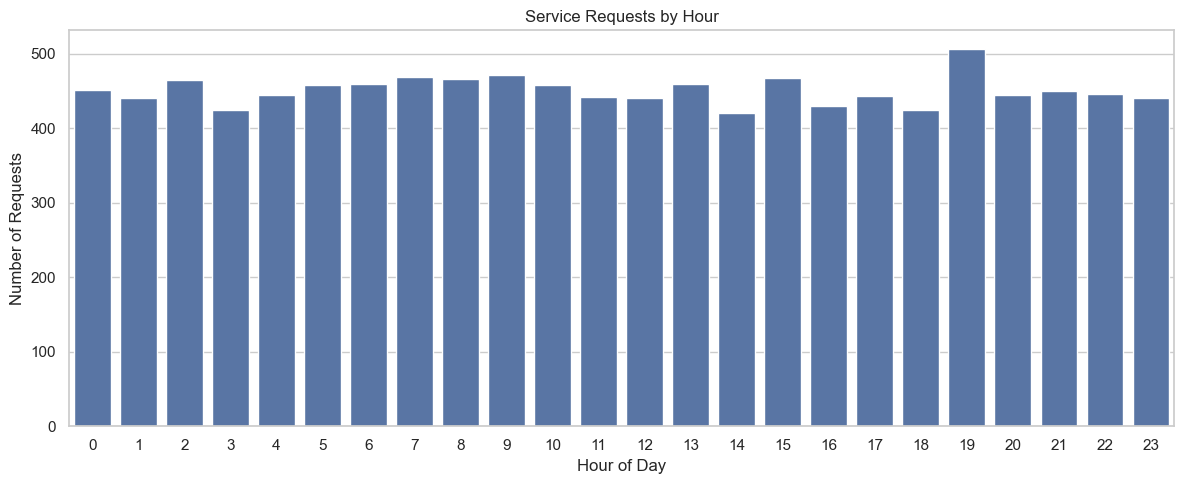

In [35]:
hourly_requests = (
    train_clean["request_hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_requests.index,
    y=hourly_requests.values
)

plt.title("Service Requests by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Requests")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

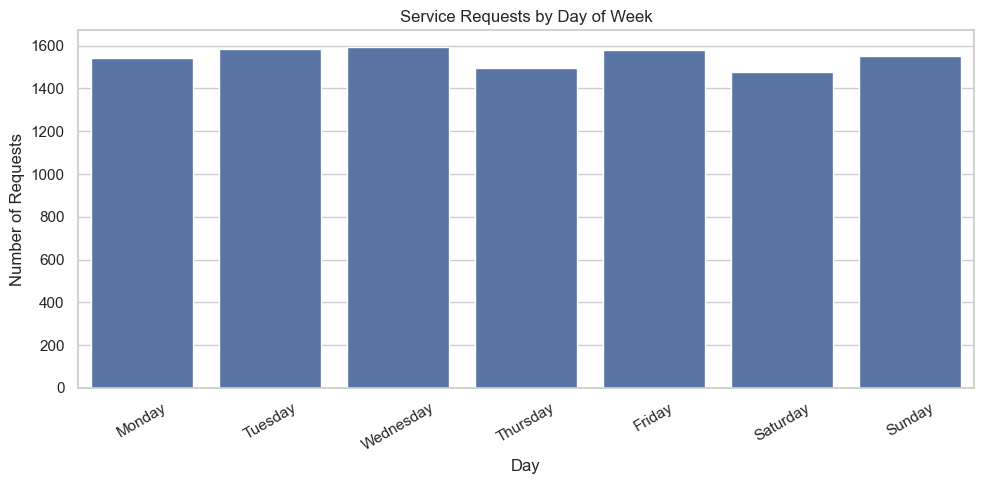

In [36]:
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

daily_requests = (
    train_clean["request_day"]
    .map(day_names)
    .value_counts()
    .reindex(list(day_names.values()))
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_requests.index,
    y=daily_requests.values
)

plt.title("Service Requests by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Requests")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

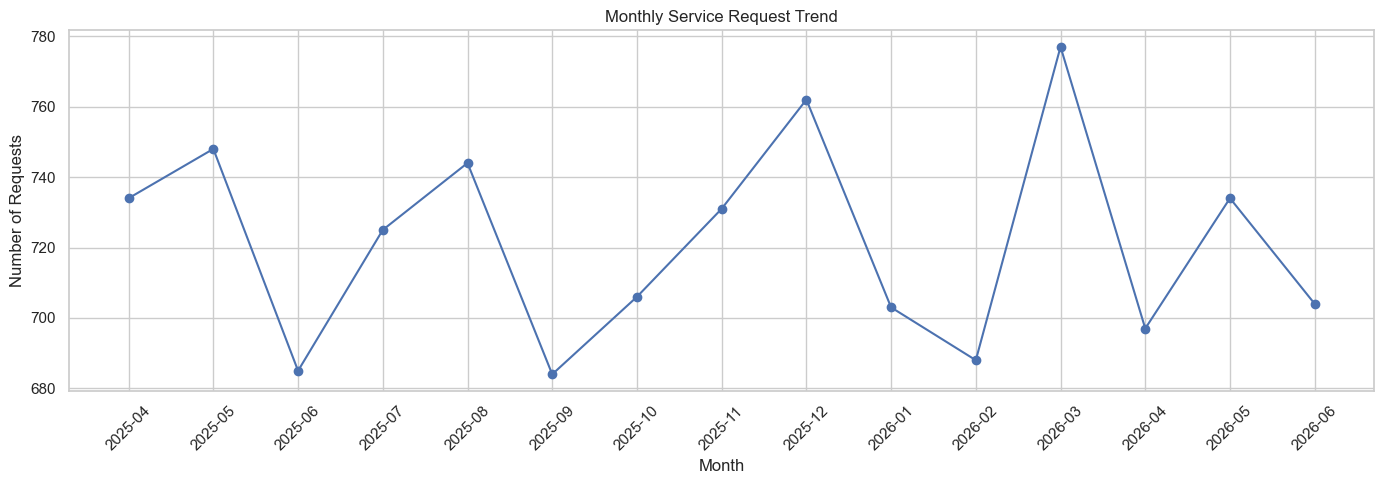

In [37]:
monthly_requests = (
    train_clean
    .groupby(train_clean["created_at_ist"].dt.to_period("M"))
    .size()
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_requests.index.astype(str),
    monthly_requests.values,
    marker="o"
)

plt.title("Monthly Service Request Trend")
plt.xlabel("Month")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
engineered_columns = [
    "created_at_ist",
    "request_hour",
    "request_day",
    "request_month",
    "request_day_of_month",
    "is_weekend",
    "time_period"
]

display(
    train_clean[engineered_columns].head(10)
)

,created_at_ist,request_hour,request_day,request_month,request_day_of_month,is_weekend,time_period
0,2025-04-01 00:31:00,0,1,4,1,0,Night
1,2025-04-01 01:27:00,1,1,4,1,0,Night
2,2025-04-01 03:26:00,3,1,4,1,0,Night
3,2025-04-01 04:50:00,4,1,4,1,0,Night
4,2025-04-01 06:39:00,6,1,4,1,0,Morning
5,2025-04-01 07:33:00,7,1,4,1,0,Morning
6,2025-04-01 09:10:00,9,1,4,1,0,Morning
7,2025-04-01 09:43:00,9,1,4,1,0,Morning
8,2025-04-01 09:59:00,9,1,4,1,0,Morning
9,2025-04-01 10:42:00,10,1,4,1,0,Morning


In [39]:
# Define numerical and categorical features

numerical_features = [
    "request_hour",
    "request_day",
    "request_month",
    "request_day_of_month",
    "is_weekend"
]

categorical_features = [
    "channel",
    "product_family",
    "warranty_status",
    "source",
    "time_period"
]

text_feature = "request_text"

# Combine all features
feature_columns = (
    [text_feature]
    + categorical_features
    + numerical_features
)

target_column = "team_label"

print("Text Feature:", text_feature)
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

print("\nTotal Input Features:", len(feature_columns))

Text Feature: request_text
Categorical Features: ['channel', 'product_family', 'warranty_status', 'source', 'time_period']
Numerical Features: ['request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend']

Total Input Features: 11


In [40]:
# Input features
X = train_clean[feature_columns].copy()

# Target variable
y = train_clean[target_column].copy()

# Unlabelled test features
X_test = test_clean[feature_columns].copy()

print("Training Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Testing Features Shape:", X_test.shape)

display(X.head())

Training Features Shape: (10822, 11)
Target Shape: (10822,)
Testing Features Shape: (2178, 11)


,request_text,channel,product_family,warranty_status,source,time_period,request_hour,request_day,request_month,request_day_of_month,is_weekend
0,sir how to clean robot vacuum reg no SR75294,whatsapp,Robot Vacuum,shield,legacy_zoho,Night,0,1,4,1,0
1,"hello team, emi conversion not done for purifi...",chat,Water Purifier,out_of_warranty,legacy_zoho,Night,1,1,4,1,0
2,claim status for purifier under warranty paid ...,whatsapp,Water Purifier,in_warranty,legacy_zoho,Night,3,1,4,1,0
3,sir spare blade set for fan available? asap,chat,Robot Vacuum,in_warranty,legacy_zoho,Night,4,1,4,1,0
4,"hi, display of air fryer gone blank thanks",ivr,Air Fryer,out_of_warranty,legacy_zoho,Morning,6,1,4,1,0


In [41]:
target_counts = y.value_counts()

target_percentage = (
    y.value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentage
})

display(target_summary)

,Count,Percentage
team_label,,
Repairs,3129,28.91
Billing,1656,15.30
Filters & Consumables,1458,13.47
Installs & Demo,1185,10.95
Product Advice,1180,10.90
Returns & Replacement,1174,10.85
Warranty Claims,1040,9.61


In [42]:
# Sort by request creation time
sorted_indices = train_clean.sort_values(
    by="created_at_ist"
).index

# Determine chronological cutoff
split_position = int(len(sorted_indices) * 0.80)

train_indices = sorted_indices[:split_position]
valid_indices = sorted_indices[split_position:]

# Create training and validation datasets
X_train = X.loc[train_indices].copy()
X_valid = X.loc[valid_indices].copy()

y_train = y.loc[train_indices].copy()
y_valid = y.loc[valid_indices].copy()

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_valid.shape)

Training Shape: (8657, 11)
Validation Shape: (2165, 11)


In [43]:
print("Training Period:")
print("Start:", train_clean.loc[train_indices, "created_at_ist"].min())
print("End:", train_clean.loc[train_indices, "created_at_ist"].max())

print("\nValidation Period:")
print("Start:", train_clean.loc[valid_indices, "created_at_ist"].min())
print("End:", train_clean.loc[valid_indices, "created_at_ist"].max())

Training Period:
Start: 2025-04-01 00:31:00
End: 2026-03-30 19:44:00

Validation Period:
Start: 2026-03-30 20:18:00
End: 2026-06-30 23:33:00


In [44]:
train_distribution = (
    y_train.value_counts(normalize=True) * 100
)

valid_distribution = (
    y_valid.value_counts(normalize=True) * 100
)

distribution_comparison = pd.DataFrame({
    "Training (%)": train_distribution,
    "Validation (%)": valid_distribution
}).fillna(0).round(2)

display(distribution_comparison)

,Training (%),Validation (%)
team_label,,
Billing,15.25,15.52
Filters & Consumables,13.50,13.35
Installs & Demo,10.97,10.85
Product Advice,11.03,10.39
Repairs,28.94,28.82
Returns & Replacement,10.63,11.73
Warranty Claims,9.68,9.33


In [45]:
train_max_date = train_clean.loc[
    train_indices, "created_at_ist"
].max()

valid_min_date = train_clean.loc[
    valid_indices, "created_at_ist"
].min()

assert train_max_date < valid_min_date

print("Chronological Split Verified!")
print("No temporal overlap between training and validation.")

Chronological Split Verified!
No temporal overlap between training and validation.


In [46]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

In [47]:
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=30000,
    sublinear_tf=True
)

print("TF-IDF Vectorizer Created Successfully!")

TF-IDF Vectorizer Created Successfully!


In [48]:
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

print("Categorical Encoder Created Successfully!")

Categorical Encoder Created Successfully!


In [49]:
numerical_transformer = StandardScaler()

print("Numerical Scaler Created Successfully!")

Numerical Scaler Created Successfully!


In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            tfidf,
            text_feature
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0.3
)

print("ColumnTransformer Created Successfully!")

ColumnTransformer Created Successfully!


In [51]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation data
X_valid_processed = preprocessor.transform(X_valid)

print("Training Processed Shape:", X_train_processed.shape)
print("Validation Processed Shape:", X_valid_processed.shape)

Training Processed Shape: (8657, 2238)
Validation Processed Shape: (2165, 2238)


In [52]:
print("Processed Data Type:",
      type(X_train_processed))

print("Training Matrix Shape:",
      X_train_processed.shape)

print("Validation Matrix Shape:",
      X_valid_processed.shape)

print("Number of Training Samples:",
      X_train_processed.shape[0])

print("Number of Extracted Features:",
      X_train_processed.shape[1])

Processed Data Type: <class 'scipy.sparse._csr.csr_matrix'>
Training Matrix Shape: (8657, 2238)
Validation Matrix Shape: (2165, 2238)
Number of Training Samples: 8657
Number of Extracted Features: 2238


In [53]:
tfidf_vocabulary = preprocessor.named_transformers_[
    "text"
].get_feature_names_out()

print("Total TF-IDF Features:",
      len(tfidf_vocabulary))

print("\nFirst 30 TF-IDF Features:")
print(tfidf_vocabulary[:30])

Total TF-IDF Features: 2213

First 30 TF-IDF Features:
['10' '10 months' '11' '11 months' '12' '12 months' '13' '13 months'
 'about' 'about air' 'about ceiling' 'about cooktop' 'about fan'
 'about fryer' 'about heater' 'about induction' 'about machine'
 'about mixa' 'about mixer' 'about product' 'about purifier' 'about robot'
 'about room' 'about vacuum' 'about water' 'after' 'after 10' 'after 11'
 'after 12' 'after 13']


In [54]:
encoded_categories = preprocessor.named_transformers_[
    "categorical"
].get_feature_names_out(categorical_features)

print("Total Categorical Features:",
      len(encoded_categories))

print("\nEncoded Features:")
print(encoded_categories)

Total Categorical Features: 20

Encoded Features:
['channel_chat' 'channel_email' 'channel_ivr' 'channel_whatsapp'
 'product_family_Air Fryer' 'product_family_Ceiling Fan'
 'product_family_Induction Cooktop' 'product_family_Mixer Grinder'
 'product_family_Robot Vacuum' 'product_family_Room Heater'
 'product_family_Water Purifier' 'warranty_status_in_warranty'
 'warranty_status_out_of_warranty' 'warranty_status_shield' 'source_crm'
 'source_legacy_zoho' 'time_period_Afternoon' 'time_period_Evening'
 'time_period_Morning' 'time_period_Night']


In [55]:
assert X_train_processed.shape[0] == len(y_train)
assert X_valid_processed.shape[0] == len(y_valid)

assert X_train_processed.shape[1] == X_valid_processed.shape[1]

print("All Preprocessing Checks Passed!")

All Preprocessing Checks Passed!


In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd
import numpy as np
import time

In [57]:
nb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                max_features=30000,
                sublinear_tf=True
            ),
            text_feature
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            MinMaxScaler(),
            numerical_features
        )
    ],
    remainder="drop"
)

print("Naive Bayes Preprocessor Created!")

Naive Bayes Preprocessor Created!


In [58]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Linear SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Complement Naive Bayes": Pipeline([
        ("preprocessor", nb_preprocessor),
        ("classifier", ComplementNB(
            alpha=0.5
        ))
    ])
}

print("Three ML Models Defined Successfully!")

Three ML Models Defined Successfully!


In [59]:
results = []

trained_models = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    start_time = time.time()

    # Train model
    model.fit(X_train, y_train)

    # Predict validation data
    y_pred = model.predict(X_valid)

    # Calculate execution time
    training_time = time.time() - start_time

    # Evaluation metrics
    accuracy = accuracy_score(y_valid, y_pred)

    precision = precision_score(
        y_valid,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_valid,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_valid,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Training Time (Seconds)": training_time
    })

    trained_models[model_name] = model

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall: {recall:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll Models Trained Successfully!")


Training: Logistic Regression
Accuracy: 0.9353
Macro Precision: 0.9272
Macro Recall: 0.9441
Macro F1: 0.9350
Weighted F1: 0.9353
Training Time: 1.18 seconds

Training: Linear SVM
Accuracy: 0.9487
Macro Precision: 0.9413
Macro Recall: 0.9546
Macro F1: 0.9476
Weighted F1: 0.9487
Training Time: 0.96 seconds

Training: Complement Naive Bayes
Accuracy: 0.8910
Macro Precision: 0.8898
Macro Recall: 0.8973
Macro F1: 0.8911
Weighted F1: 0.8896
Training Time: 0.27 seconds

All Models Trained Successfully!


In [60]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Training Time (Seconds)": "{:.2f}"
    })
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (Seconds)
0,Linear SVM,0.9487,0.9413,0.9546,0.9476,0.9487,0.96
1,Logistic Regression,0.9353,0.9272,0.9441,0.9350,0.9353,1.18
2,Complement Naive Bayes,0.8910,0.8898,0.8973,0.8911,0.8896,0.27


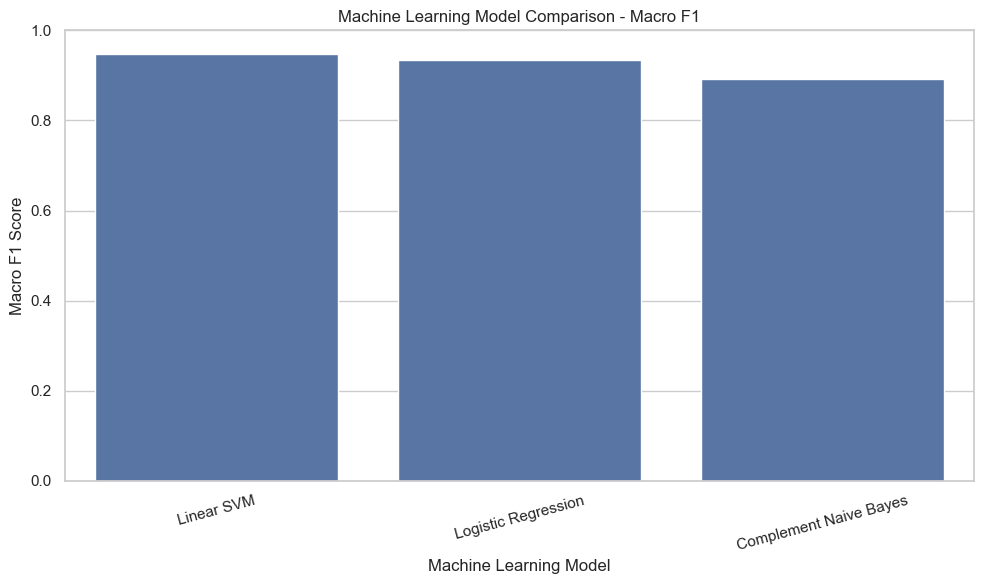

In [61]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro F1"
)

plt.title("Machine Learning Model Comparison - Macro F1")
plt.xlabel("Machine Learning Model")
plt.ylabel("Macro F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [62]:
for model_name, model in trained_models.items():

    print("\n" + "=" * 70)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 70)

    y_pred = model.predict(X_valid)

    print(
        classification_report(
            y_valid,
            y_pred,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
                       precision    recall  f1-score   support

              Billing       0.92      0.97      0.95       336
Filters & Consumables       0.91      0.93      0.92       289
      Installs & Demo       0.93      0.98      0.95       235
       Product Advice       0.92      0.96      0.94       225
              Repairs       0.99      0.89      0.94       624
Returns & Replacement       0.93      0.93      0.93       254
      Warranty Claims       0.91      0.95      0.93       202

             accuracy                           0.94      2165
            macro avg       0.93      0.94      0.93      2165
         weighted avg       0.94      0.94      0.94      2165


CLASSIFICATION REPORT: Linear SVM
                       precision    recall  f1-score   support

              Billing       0.95      0.98      0.97       336
Filters & Consumables       0.92      0.96      0.94       289
      Installs & Demo       0.94   

In [63]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Baseline Model:", best_model_name)
print(
    "Best Macro F1:",
    round(results_df.iloc[0]["Macro F1"], 4)
)

Best Baseline Model: Linear SVM
Best Macro F1: 0.9476


In [64]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

In [65]:
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LinearSVC(
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

print("Linear SVM Pipeline Created Successfully!")

Linear SVM Pipeline Created Successfully!


In [66]:
param_grid = {
    "classifier__C": [0.1, 0.5, 1.0, 1.5, 2.0, 3.0],

    "classifier__class_weight": [
        "balanced",
        None
    ]
}

print("Hyperparameter Grid:")
print(param_grid)

Hyperparameter Grid:
{'classifier__C': [0.1, 0.5, 1.0, 1.5, 2.0, 3.0], 'classifier__class_weight': ['balanced', None]}


In [67]:
time_cv = TimeSeriesSplit(n_splits=4)

print("Time Series Cross Validation Created!")
print("Number of Splits:", time_cv.n_splits)

Time Series Cross Validation Created!
Number of Splits: 4


In [68]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=time_cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Hyperparameter Tuning Completed!")

Fitting 4 folds for each of 12 candidates, totalling 48 fits
Hyperparameter Tuning Completed!


In [69]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'classifier__C': 1.5, 'classifier__class_weight': None}

Best Cross-Validation Macro F1:
0.9493


In [70]:
grid_results = pd.DataFrame(
    grid_search.cv_results_
)

grid_results = grid_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values(
    by="rank_test_score"
)

display(grid_results)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
7,1.5,None,0.949282,0.011466,1
9,2.0,None,0.948663,0.011316,2
11,3.0,None,0.948079,0.010285,3
5,1.0,None,0.948060,0.012364,4
6,1.5,balanced,0.948032,0.011658,5
8,2.0,balanced,0.947991,0.012216,6
10,3.0,balanced,0.947395,0.012053,7
4,1.0,balanced,0.946640,0.012147,8
3,0.5,None,0.946294,0.011926,9
2,0.5,balanced,0.943808,0.012394,10


In [71]:
best_svm_model = grid_search.best_estimator_

y_pred_tuned = best_svm_model.predict(X_valid)

tuned_accuracy = accuracy_score(
    y_valid,
    y_pred_tuned
)

tuned_precision = precision_score(
    y_valid,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_recall = recall_score(
    y_valid,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_macro_f1 = f1_score(
    y_valid,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_weighted_f1 = f1_score(
    y_valid,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

print("TUNED LINEAR SVM PERFORMANCE")
print("-" * 45)

print(f"Accuracy: {tuned_accuracy:.4f}")
print(f"Macro Precision: {tuned_precision:.4f}")
print(f"Macro Recall: {tuned_recall:.4f}")
print(f"Macro F1: {tuned_macro_f1:.4f}")
print(f"Weighted F1: {tuned_weighted_f1:.4f}")

TUNED LINEAR SVM PERFORMANCE
---------------------------------------------
Accuracy: 0.9529
Macro Precision: 0.9468
Macro Recall: 0.9561
Macro F1: 0.9512
Weighted F1: 0.9529


In [72]:
baseline_svm = trained_models["Linear SVM"]

baseline_predictions = baseline_svm.predict(X_valid)

baseline_macro_f1 = f1_score(
    y_valid,
    baseline_predictions,
    average="macro"
)

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline Linear SVM",
        "Tuned Linear SVM"
    ],

    "Macro F1": [
        baseline_macro_f1,
        tuned_macro_f1
    ],

    "Accuracy": [
        accuracy_score(y_valid, baseline_predictions),
        tuned_accuracy
    ]
})

display(comparison_df)

,Model,Macro F1,Accuracy
0,Baseline Linear SVM,0.947553,0.948730
1,Tuned Linear SVM,0.951227,0.952887


In [73]:
print(
    classification_report(
        y_valid,
        y_pred_tuned,
        zero_division=0
    )
)

                       precision    recall  f1-score   support

              Billing       0.96      0.98      0.97       336
Filters & Consumables       0.92      0.95      0.94       289
      Installs & Demo       0.94      0.97      0.96       235
       Product Advice       0.94      0.96      0.95       225
              Repairs       0.98      0.93      0.96       624
Returns & Replacement       0.95      0.94      0.94       254
      Warranty Claims       0.94      0.95      0.94       202

             accuracy                           0.95      2165
            macro avg       0.95      0.96      0.95      2165
         weighted avg       0.95      0.95      0.95      2165



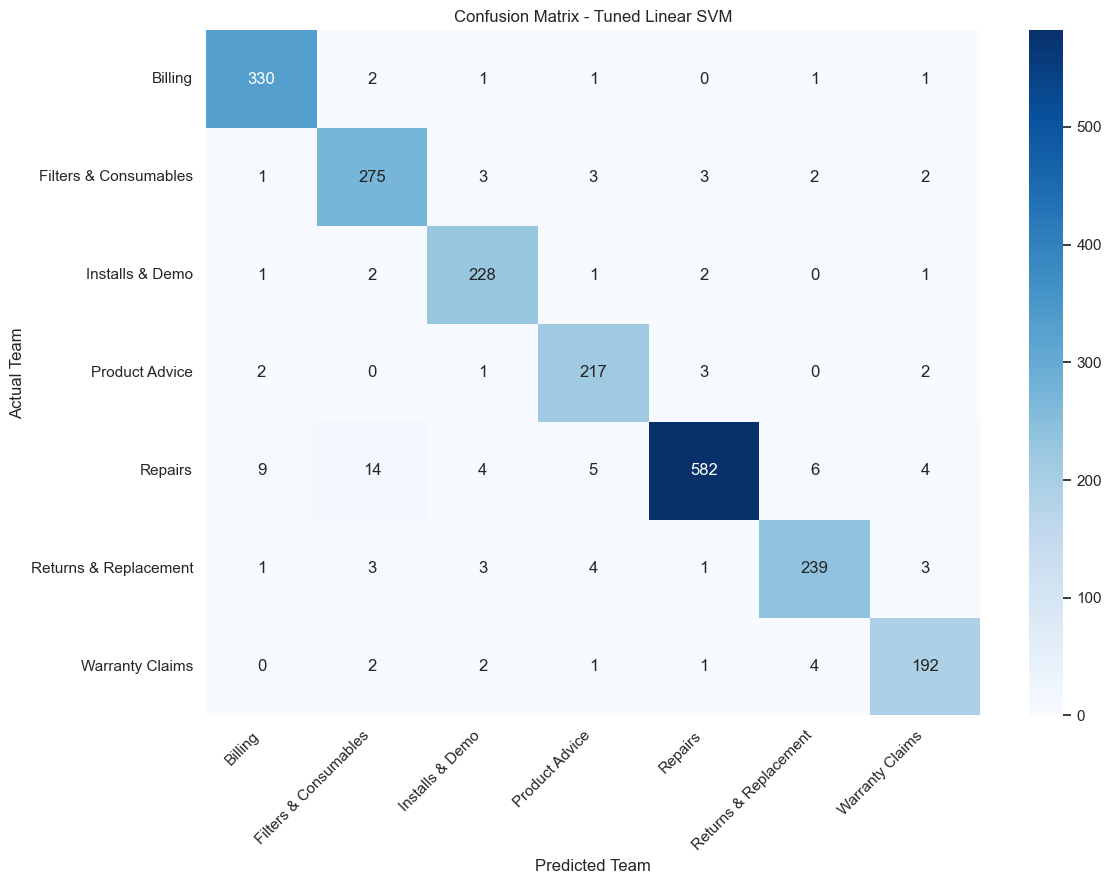

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = best_svm_model.named_steps[
    "classifier"
].classes_

cm = confusion_matrix(
    y_valid,
    y_pred_tuned,
    labels=class_labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Tuned Linear SVM")
plt.xlabel("Predicted Team")
plt.ylabel("Actual Team")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_valid,
        y_pred_tuned,
        labels=class_labels,
        zero_division=0
    )
)

class_performance = pd.DataFrame({
    "Team": class_labels,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Support": support
})

display(
    class_performance.sort_values(
        "F1 Score",
        ascending=True
    )
)

,Team,Precision,Recall,F1 Score,Support
1,Filters & Consumables,0.922819,0.951557,0.936968,289
6,Warranty Claims,0.936585,0.950495,0.943489,202
5,Returns & Replacement,0.948413,0.940945,0.944664,254
3,Product Advice,0.935345,0.964444,0.949672,225
2,Installs & Demo,0.942149,0.970213,0.955975,235
4,Repairs,0.983108,0.932692,0.957237,624
0,Billing,0.959302,0.982143,0.970588,336


In [76]:
error_analysis = X_valid.copy()

error_analysis["Actual Team"] = y_valid
error_analysis["Predicted Team"] = y_pred_tuned

error_analysis["Correct"] = (
    error_analysis["Actual Team"]
    == error_analysis["Predicted Team"]
)

incorrect_predictions = error_analysis[
    error_analysis["Correct"] == False
].copy()

print("Total Validation Records:", len(error_analysis))
print("Correct Predictions:", error_analysis["Correct"].sum())
print("Incorrect Predictions:", len(incorrect_predictions))

display(
    incorrect_predictions[
        [
            "request_text",
            "channel",
            "product_family",
            "warranty_status",
            "Actual Team",
            "Predicted Team"
        ]
    ].head(20)
)

Total Validation Records: 2165
Correct Predictions: 2063
Incorrect Predictions: 102


,request_text,channel,product_family,warranty_status,Actual Team,Predicted Team
8723,water purifier leaking water from bottom reg n...,whatsapp,Water Purifier,shield,Repairs,Filters & Consumables
8750,"hi, order candle and membrane for machine pls ...",chat,Room Heater,in_warranty,Warranty Claims,Filters & Consumables
8757,"hello team, need warranty certificate water pu...",ivr,Water Purifier,in_warranty,Filters & Consumables,Warranty Claims
8772,urgent: issue with machine order KO2605204 thanks,ivr,Water Purifier,in_warranty,Filters & Consumables,Repairs
8788,complaint about induction cooktop payment done,chat,Induction Cooktop,in_warranty,Repairs,Billing
8799,sir warranty claim for water purifier bought 9...,whatsapp,Water Purifier,out_of_warranty,Repairs,Warranty Claims
8802,"pls help - box was open, fan scratched, fan qu...",ivr,Room Heater,out_of_warranty,Repairs,Returns & Replacement
8814,filter change reminder for purifier,email,Water Purifier,shield,Warranty Claims,Filters & Consumables
8853,"hi, air fryer delivered but not installed yet,...",whatsapp,Air Fryer,in_warranty,Filters & Consumables,Installs & Demo
8856,"good morning, consumable pack for water purifi...",chat,Water Purifier,shield,Installs & Demo,Filters & Consumables


In [77]:
routing_errors = (
    incorrect_predictions
    .groupby(["Actual Team", "Predicted Team"])
    .size()
    .reset_index(name="Error Count")
    .sort_values(
        "Error Count",
        ascending=False
    )
)

display(routing_errors.head(15))

,Actual Team,Predicted Team,Error Count
21,Repairs,Filters & Consumables,14
20,Repairs,Billing,9
24,Repairs,Returns & Replacement,6
23,Repairs,Product Advice,5
22,Repairs,Installs & Demo,4
29,Returns & Replacement,Product Advice,4
36,Warranty Claims,Returns & Replacement,4
25,Repairs,Warranty Claims,4
27,Returns & Replacement,Filters & Consumables,3
18,Product Advice,Repairs,3


In [78]:
total_predictions = len(y_valid)

correct_predictions = (
    y_valid == y_pred_tuned
).sum()

incorrect_count = (
    y_valid != y_pred_tuned
).sum()

print("Total Predictions:", total_predictions)
print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_count)

print(
    "Validation Accuracy:",
    round(correct_predictions / total_predictions * 100, 2),
    "%"
)

Total Predictions: 2165
Correct Predictions: 2063
Incorrect Predictions: 102
Validation Accuracy: 95.29 %


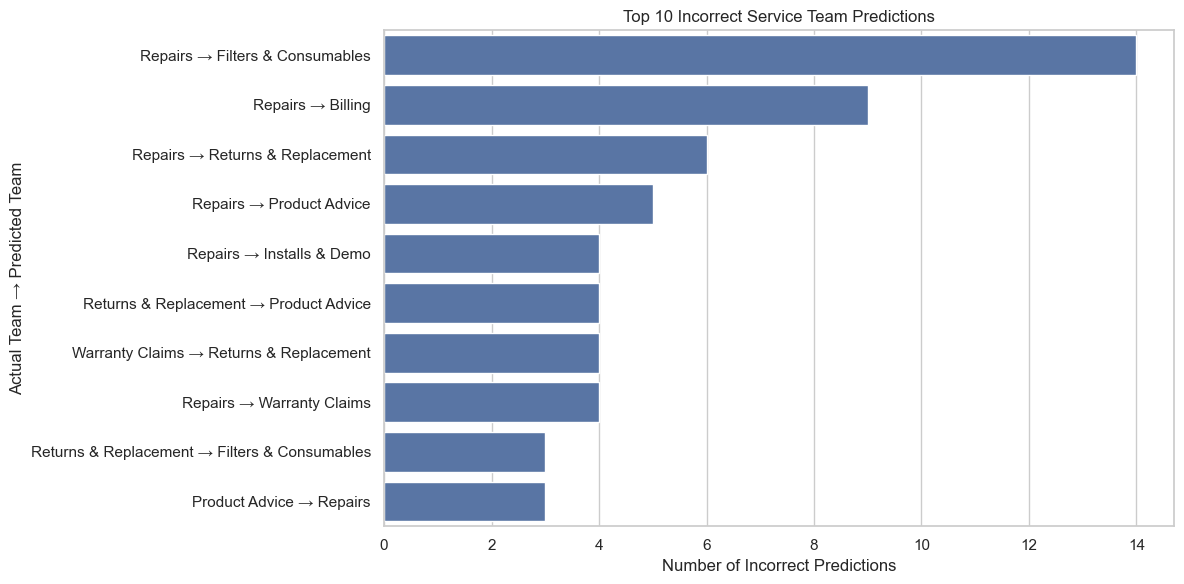

In [79]:
top_errors = routing_errors.head(10).copy()

top_errors["Routing Pair"] = (
    top_errors["Actual Team"]
    + " → "
    + top_errors["Predicted Team"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_errors,
    x="Error Count",
    y="Routing Pair"
)

plt.title("Top 10 Incorrect Service Team Predictions")
plt.xlabel("Number of Incorrect Predictions")
plt.ylabel("Actual Team → Predicted Team")
plt.tight_layout()
plt.show()

In [80]:
print("TEAM DEFINITIONS")
display(teams_df)

print("\nTEAM DATASET COLUMNS")
print(teams_df.columns.tolist())

TEAM DEFINITIONS


,team,renamed_to,handles
0,Installations,Installs & Demo (from 15 Jan 2026),"New-product installation, demo and wall-mounti..."
1,Repairs,NaN,"Product faults, breakdowns, error codes, noise..."
2,Consumables,Filters & Consumables (from 15 Jan 2026),"Filters, candles, membranes, jars, brushes, bl..."
3,Billing,NaN,"Invoices, GST, double charges, refunds of paym..."
4,Returns & Replacement,NaN,"Damaged, wrong or incomplete deliveries; retur..."
5,Warranty Claims,NaN,"Warranty and Kestrel Shield registration, cove..."
6,Product Advice,NaN,Pre- and post-purchase usage questions. No fau...



TEAM DATASET COLUMNS
['team', 'renamed_to', 'handles']


In [81]:
print("RESOLUTION LOG INFORMATION")
resolution_df.info()

print("\nRESOLUTION LOG SAMPLE")
display(resolution_df.head(10))

print("\nRESOLUTION LOG COLUMNS")
print(resolution_df.columns.tolist())

RESOLUTION LOG INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10822 entries, 0 to 10821
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   request_id   10822 non-null  object
 1   first_team   10822 non-null  object
 2   final_team   10822 non-null  object
 3   transfers    10822 non-null  int64 
 4   resolved_at  10822 non-null  object
dtypes: int64(1), object(4)
memory usage: 422.9+ KB

RESOLUTION LOG SAMPLE


,request_id,first_team,final_team,transfers,resolved_at
0,SR500000,Product Advice,Product Advice,0,2025-04-01 11:04
1,SR500001,Billing,Billing,0,2025-03-31 22:41
2,SR500002,Billing,Warranty Claims,1,2025-04-01 13:26
3,SR500003,Consumables,Consumables,0,2025-04-01 11:07
4,SR500004,Repairs,Repairs,1,2025-04-01 09:18
5,SR500005,Consumables,Consumables,0,2025-04-01 12:46
6,SR500006,Installations,Installations,0,2025-04-01 16:43
7,SR500007,Billing,Billing,0,2025-04-01 07:06
8,SR500008,Billing,Warranty Claims,1,2025-04-01 16:38
9,SR500009,Consumables,Consumables,0,2025-04-02 06:52



RESOLUTION LOG COLUMNS
['request_id', 'first_team', 'final_team', 'transfers', 'resolved_at']


In [82]:
print("Resolution Log Columns:")
print(resolution_df.columns.tolist())

Resolution Log Columns:
['request_id', 'first_team', 'final_team', 'transfers', 'resolved_at']


In [83]:
team_related_columns = [
    column for column in resolution_df.columns
    if "team" in column.lower()
]

print("Team-Related Columns:")
print(team_related_columns)

display(
    resolution_df[team_related_columns].head(10)
)

Team-Related Columns:
['first_team', 'final_team']


,first_team,final_team
0,Product Advice,Product Advice
1,Billing,Billing
2,Billing,Warranty Claims
3,Consumables,Consumables
4,Repairs,Repairs
5,Consumables,Consumables
6,Installations,Installations
7,Billing,Billing
8,Billing,Warranty Claims
9,Consumables,Consumables


In [84]:
# Inspect actual routing errors
display(
    incorrect_predictions[
        incorrect_predictions["Actual Team"].eq("Repairs")
    ][
        [
            "request_text",
            "product_family",
            "warranty_status",
            "Actual Team",
            "Predicted Team"
        ]
    ].head(30)
)

,request_text,product_family,warranty_status,Actual Team,Predicted Team
8723,water purifier leaking water from bottom reg n...,Water Purifier,shield,Repairs,Filters & Consumables
8788,complaint about induction cooktop payment done,Induction Cooktop,in_warranty,Repairs,Billing
8799,sir warranty claim for water purifier bought 9...,Water Purifier,out_of_warranty,Repairs,Warranty Claims
8802,"pls help - box was open, fan scratched, fan qu...",Room Heater,out_of_warranty,Repairs,Returns & Replacement
9003,purifier showing error code E3 purifier not wo...,Water Purifier,shield,Repairs,Filters & Consumables
9008,"sir invoice not received for heater, heater tr...",Ceiling Fan,out_of_warranty,Repairs,Billing
9146,"hi, ceiling fan query already paid in full reg...",Ceiling Fan,in_warranty,Repairs,Billing
9162,urgent: installer did not turn up for ceiling ...,Ceiling Fan,shield,Repairs,Installs & Demo
9243,pls help - water purifier stopped working afte...,Water Purifier,in_warranty,Repairs,Filters & Consumables
9260,"namaste, machine query already paid in full ki...",Mixer Grinder,out_of_warranty,Repairs,Billing


In [85]:
# Get decision scores
decision_scores = best_svm_model.decision_function(X_valid)

# Sort scores for each prediction
sorted_scores = np.sort(decision_scores, axis=1)

# Difference between highest and second-highest score
confidence_margin = sorted_scores[:, -1] - sorted_scores[:, -2]

confidence_analysis = pd.DataFrame({
    "Request Text": X_valid["request_text"].values,
    "Actual Team": y_valid.values,
    "Predicted Team": y_pred_tuned,
    "Confidence Margin": confidence_margin,
    "Correct": y_valid.values == y_pred_tuned
})

display(
    confidence_analysis.sort_values(
        "Confidence Margin"
    ).head(20)
)

,Request Text,Actual Team,Predicted Team,Confidence Margin,Correct
517,urgent: invoice not received for water purifie...,Warranty Claims,Warranty Claims,0.000119,True
1059,"namaste, filter change reminder for induction ...",Repairs,Filters & Consumables,0.003210,False
1586,urgent: claim status for water purifier under ...,Returns & Replacement,Returns & Replacement,0.003972,True
1500,"good morning, water purifier showing error cod...",Filters & Consumables,Filters & Consumables,0.007544,True
1982,"hi, product missing parts in box, need help wi...",Repairs,Repairs,0.011328,True
144,"pls help - box was open, fan scratched, fan qu...",Repairs,Returns & Replacement,0.015208,False
943,"hello team, need warranty certificate ceiling ...",Repairs,Repairs,0.018675,True
1433,"urgent: how to clean air fryer, want AMC filte...",Filters & Consumables,Product Advice,0.023895,False
1771,"namaste, wall mounting for robot vacuum pendin...",Repairs,Installs & Demo,0.028467,False
330,"hello team, water purifier leaking water from ...",Filters & Consumables,Filters & Consumables,0.028486,True


In [86]:
low_confidence_requests = confidence_analysis[
    confidence_analysis["Confidence Margin"] < 0.20
].copy()

print("Total Low-Margin Predictions:",
      len(low_confidence_requests))

print("\nLow-Margin Prediction Accuracy:",
      low_confidence_requests["Correct"].mean())

display(low_confidence_requests.head(20))

Total Low-Margin Predictions: 39

Low-Margin Prediction Accuracy: 0.5641025641025641


,Request Text,Actual Team,Predicted Team,Confidence Margin,Correct
20,"namaste, best settings for water purifier, wat...",Filters & Consumables,Filters & Consumables,0.197481,True
87,sir invoice not received for induction cooktop...,Installs & Demo,Installs & Demo,0.168093,True
131,complaint about induction cooktop payment done,Repairs,Billing,0.071645,False
144,"pls help - box was open, fan scratched, fan qu...",Repairs,Returns & Replacement,0.015208,False
156,"hi, service request for water purifier i paid ...",Filters & Consumables,Filters & Consumables,0.087897,True
199,"good morning, consumable pack for water purifi...",Installs & Demo,Filters & Consumables,0.038230,False
279,warranty claim for water purifier bought 3 mon...,Filters & Consumables,Filters & Consumables,0.136149,True
311,pls help - warranty card for water purifier no...,Filters & Consumables,Filters & Consumables,0.179383,True
330,"hello team, water purifier leaking water from ...",Filters & Consumables,Filters & Consumables,0.028486,True
474,"hi, warranty card for mixer not registered, wr...",Returns & Replacement,Warranty Claims,0.039687,False


In [87]:
# Create a copy of resolution history
resolution_clean = resolution_df.copy()

# Standardize historical team names
team_mapping = {
    "Installations": "Installs & Demo",
    "Consumables": "Filters & Consumables"
}

resolution_clean["first_team"] = (
    resolution_clean["first_team"].replace(team_mapping)
)

resolution_clean["final_team"] = (
    resolution_clean["final_team"].replace(team_mapping)
)

print("Standardized Resolution History:")
display(resolution_clean.head())

Standardized Resolution History:


,request_id,first_team,final_team,transfers,resolved_at
0,SR500000,Product Advice,Product Advice,0,2025-04-01 11:04
1,SR500001,Billing,Billing,0,2025-03-31 22:41
2,SR500002,Billing,Warranty Claims,1,2025-04-01 13:26
3,SR500003,Filters & Consumables,Filters & Consumables,0,2025-04-01 11:07
4,SR500004,Repairs,Repairs,1,2025-04-01 09:18


In [88]:
print("Initial Team Distribution")

display(
    resolution_clean["first_team"]
    .value_counts()
    .to_frame("Request Count")
)

print("\nFinal Team Distribution")

display(
    resolution_clean["final_team"]
    .value_counts()
    .to_frame("Request Count")
)

Initial Team Distribution


,Request Count
first_team,
Repairs,3129
Billing,1656
Filters & Consumables,1458
Installs & Demo,1185
Product Advice,1180
Returns & Replacement,1174
Warranty Claims,1040



Final Team Distribution


,Request Count
final_team,
Repairs,2534
Installs & Demo,1596
Returns & Replacement,1539
Product Advice,1390
Warranty Claims,1379
Billing,1318
Filters & Consumables,1066


In [89]:
total_requests = len(resolution_clean)

transferred_requests = (
    resolution_clean["transfers"] > 0
).sum()

no_transfer_requests = (
    resolution_clean["transfers"] == 0
).sum()

transfer_percentage = (
    transferred_requests / total_requests
) * 100

print("Total Requests:", total_requests)
print("Requests With Transfers:", transferred_requests)
print("Requests Without Transfers:", no_transfer_requests)

print(f"Transfer Percentage: {transfer_percentage:.2f}%")

Total Requests: 10822
Requests With Transfers: 2696
Requests Without Transfers: 8126
Transfer Percentage: 24.91%


In [90]:
transfer_analysis = (
    resolution_clean
    .groupby("first_team")
    .agg(
        Total_Requests=("request_id", "count"),
        Total_Transfers=("transfers", "sum"),
        Average_Transfers=("transfers", "mean"),
        Requests_With_Transfers=(
            "transfers",
            lambda x: (x > 0).sum()
        )
    )
)

transfer_analysis["Transfer_Rate_Percentage"] = (
    transfer_analysis["Requests_With_Transfers"]
    / transfer_analysis["Total_Requests"]
) * 100

transfer_analysis = transfer_analysis.sort_values(
    "Transfer_Rate_Percentage",
    ascending=False
)

display(transfer_analysis.round(2))

,Total_Requests,Total_Transfers,Average_Transfers,Requests_With_Transfers,Transfer_Rate_Percentage
first_team,,,,,
Filters & Consumables,1458,870,0.60,601,41.22
Repairs,3129,1785,0.57,1202,38.41
Billing,1656,920,0.56,611,36.90
Product Advice,1180,89,0.08,78,6.61
Warranty Claims,1040,74,0.07,65,6.25
Returns & Replacement,1174,84,0.07,70,5.96
Installs & Demo,1185,80,0.07,69,5.82


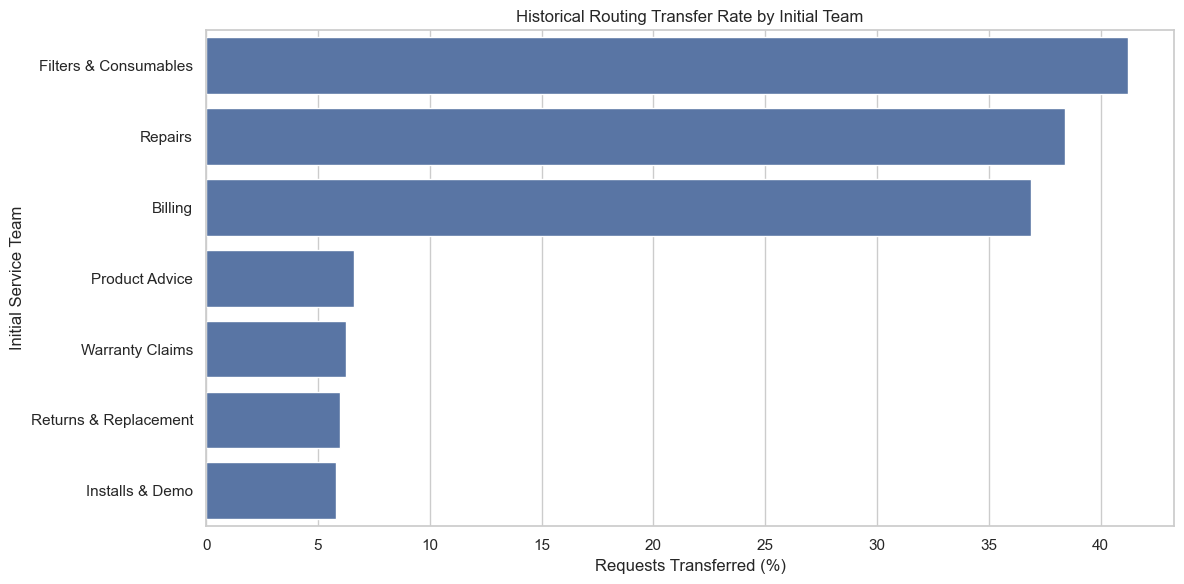

In [91]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=transfer_analysis.reset_index(),
    x="Transfer_Rate_Percentage",
    y="first_team"
)

plt.title("Historical Routing Transfer Rate by Initial Team")
plt.xlabel("Requests Transferred (%)")
plt.ylabel("Initial Service Team")
plt.tight_layout()
plt.show()

final_team,Billing,Filters & Consumables,Installs & Demo,Product Advice,Repairs,Returns & Replacement,Warranty Claims
first_team,,,,,,,
Billing,1071,9,146,7,192,125,106
Filters & Consumables,43,872,67,40,315,56,65
Installs & Demo,7,7,1146,10,10,2,3
Product Advice,9,9,6,1135,9,4,8
Repairs,178,157,218,182,1993,214,187
Returns & Replacement,6,7,7,7,7,1132,8
Warranty Claims,4,5,6,9,8,6,1002


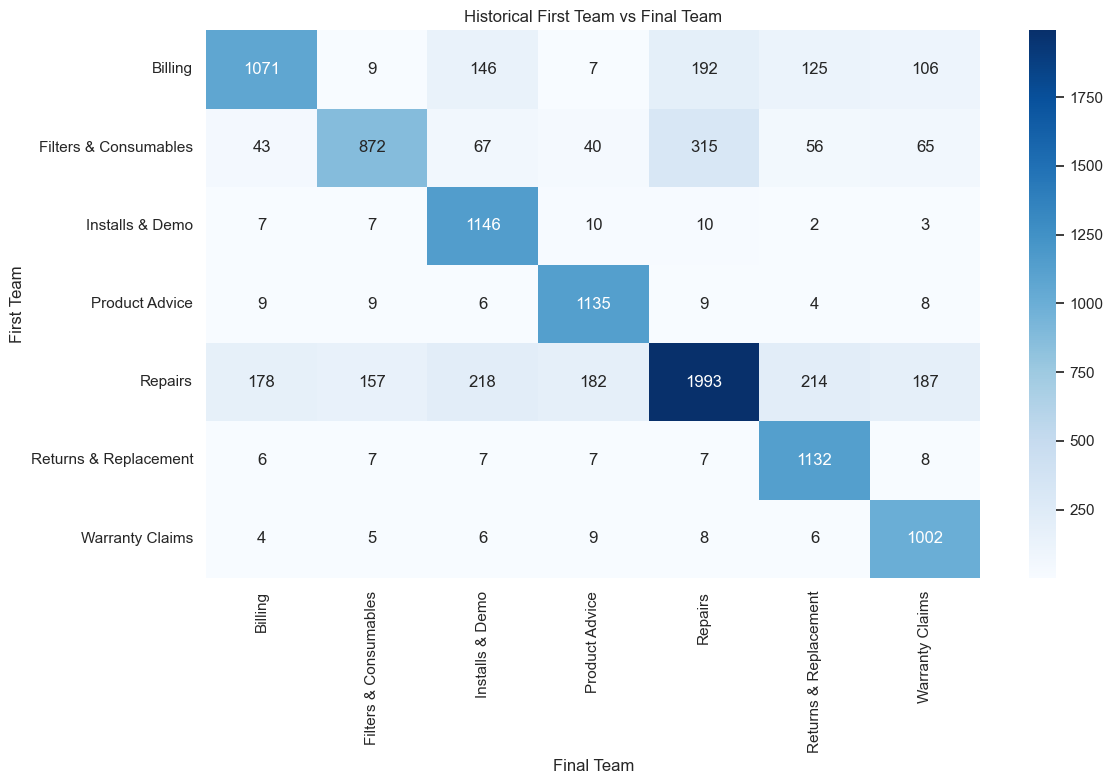

In [92]:
routing_matrix = pd.crosstab(
    resolution_clean["first_team"],
    resolution_clean["final_team"]
)

display(routing_matrix)

plt.figure(figsize=(12, 8))

sns.heatmap(
    routing_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Historical First Team vs Final Team")
plt.xlabel("Final Team")
plt.ylabel("First Team")
plt.tight_layout()
plt.show()

In [93]:
team_transfers = (
    resolution_clean[
        resolution_clean["first_team"]
        != resolution_clean["final_team"]
    ]
    .groupby(["first_team", "final_team"])
    .size()
    .reset_index(name="Transfer_Count")
    .sort_values("Transfer_Count", ascending=False)
)

print("Most Common Historical Team Transfers:")

display(team_transfers.head(20))

Most Common Historical Team Transfers:


,first_team,final_team,Transfer_Count
9,Filters & Consumables,Repairs,315
26,Repairs,Installs & Demo,218
28,Repairs,Returns & Replacement,214
3,Billing,Repairs,192
29,Repairs,Warranty Claims,187
27,Repairs,Product Advice,182
24,Repairs,Billing,178
25,Repairs,Filters & Consumables,157
1,Billing,Installs & Demo,146
4,Billing,Returns & Replacement,125


In [94]:
routing_audit = train_clean[
    ["request_id", "team_label"]
].merge(
    resolution_clean[
        ["request_id", "first_team", "final_team", "transfers"]
    ],
    on="request_id",
    how="inner",
    validate="one_to_one"
)

routing_audit["Label_Matches_Final_Team"] = (
    routing_audit["team_label"]
    == routing_audit["final_team"]
)

print("Training Records Matched:", len(routing_audit))

print(
    "Target Matches Historical Final Team:",
    routing_audit["Label_Matches_Final_Team"].mean()
)

display(
    routing_audit[
        routing_audit["Label_Matches_Final_Team"] == False
    ].head(20)
)

Training Records Matched: 10822
Target Matches Historical Final Team: 0.7716688227684346


,request_id,team_label,first_team,final_team,transfers,Label_Matches_Final_Team
2,SR500002,Billing,Billing,Warranty Claims,1,False
8,SR500008,Billing,Billing,Warranty Claims,1,False
12,SR500012,Repairs,Repairs,Product Advice,1,False
23,SR500023,Billing,Billing,Repairs,2,False
31,SR500031,Repairs,Repairs,Product Advice,2,False
33,SR500033,Warranty Claims,Warranty Claims,Installs & Demo,1,False
41,SR500041,Filters & Consumables,Filters & Consumables,Warranty Claims,1,False
48,SR500048,Repairs,Repairs,Billing,2,False
51,SR500051,Filters & Consumables,Filters & Consumables,Repairs,1,False
52,SR500052,Repairs,Repairs,Warranty Claims,1,False


In [95]:
print("Official Team Definitions")

display(teams_df)

print("\nTeam Definition Columns:")
print(teams_df.columns.tolist())

Official Team Definitions


,team,renamed_to,handles
0,Installations,Installs & Demo (from 15 Jan 2026),"New-product installation, demo and wall-mounti..."
1,Repairs,NaN,"Product faults, breakdowns, error codes, noise..."
2,Consumables,Filters & Consumables (from 15 Jan 2026),"Filters, candles, membranes, jars, brushes, bl..."
3,Billing,NaN,"Invoices, GST, double charges, refunds of paym..."
4,Returns & Replacement,NaN,"Damaged, wrong or incomplete deliveries; retur..."
5,Warranty Claims,NaN,"Warranty and Kestrel Shield registration, cove..."
6,Product Advice,NaN,Pre- and post-purchase usage questions. No fau...



Team Definition Columns:
['team', 'renamed_to', 'handles']


In [96]:
# Merge target with historical routing information
target_audit = train_clean[
    ["request_id", "team_label"]
].merge(
    resolution_clean[
        ["request_id", "first_team", "final_team"]
    ],
    on="request_id",
    how="inner",
    validate="one_to_one"
)

# Compare target with historical teams
target_audit["Matches_First_Team"] = (
    target_audit["team_label"]
    == target_audit["first_team"]
)

target_audit["Matches_Final_Team"] = (
    target_audit["team_label"]
    == target_audit["final_team"]
)

print("Total Matched Records:", len(target_audit))

print(
    "Matches First Team:",
    target_audit["Matches_First_Team"].mean() * 100,
    "%"
)

print(
    "Matches Final Team:",
    target_audit["Matches_Final_Team"].mean() * 100,
    "%"
)

Total Matched Records: 10822
Matches First Team: 100.0 %
Matches Final Team: 77.16688227684347 %


In [97]:
first_team_mismatches = target_audit[
    target_audit["Matches_First_Team"] == False
]

final_team_mismatches = target_audit[
    target_audit["Matches_Final_Team"] == False
]

print("First Team Mismatches:")
display(first_team_mismatches.head(15))

print("\nFinal Team Mismatches:")
display(final_team_mismatches.head(15))

First Team Mismatches:


,request_id,team_label,first_team,final_team,Matches_First_Team,Matches_Final_Team



Final Team Mismatches:


,request_id,team_label,first_team,final_team,Matches_First_Team,Matches_Final_Team
2,SR500002,Billing,Billing,Warranty Claims,True,False
8,SR500008,Billing,Billing,Warranty Claims,True,False
12,SR500012,Repairs,Repairs,Product Advice,True,False
23,SR500023,Billing,Billing,Repairs,True,False
31,SR500031,Repairs,Repairs,Product Advice,True,False
33,SR500033,Warranty Claims,Warranty Claims,Installs & Demo,True,False
41,SR500041,Filters & Consumables,Filters & Consumables,Warranty Claims,True,False
48,SR500048,Repairs,Repairs,Billing,True,False
51,SR500051,Filters & Consumables,Filters & Consumables,Repairs,True,False
52,SR500052,Repairs,Repairs,Warranty Claims,True,False


In [98]:
TRANSFER_COST = 305
EXTRA_CONTACT_COST = 260
ANNUAL_LICENCE_COST = 320000

# Historical routing costs
total_transfers = resolution_clean["transfers"].sum()

requests_with_transfers = (
    resolution_clean["transfers"] > 0
).sum()

transfer_cost = total_transfers * TRANSFER_COST

extra_contact_cost = (
    requests_with_transfers * EXTRA_CONTACT_COST
)

total_routing_cost = (
    transfer_cost + extra_contact_cost
)

print("Total Transfers:", total_transfers)

print("Transfer Cost: ₹",
      round(transfer_cost, 2))

print("Additional Contact Cost: ₹",
      round(extra_contact_cost, 2))

print("Estimated Total Routing Cost: ₹",
      round(total_routing_cost, 2))

Total Transfers: 3902
Transfer Cost: ₹ 1190110
Additional Contact Cost: ₹ 700960
Estimated Total Routing Cost: ₹ 1891070


In [99]:
team_cost_analysis = (
    resolution_clean
    .groupby("first_team")
    .agg(
        Requests=("request_id", "count"),
        Transfers=("transfers", "sum"),
        Requests_Transferred=(
            "transfers",
            lambda x: (x > 0).sum()
        )
    )
)

team_cost_analysis["Transfer_Cost"] = (
    team_cost_analysis["Transfers"] * TRANSFER_COST
)

team_cost_analysis["Extra_Contact_Cost"] = (
    team_cost_analysis["Requests_Transferred"]
    * EXTRA_CONTACT_COST
)

team_cost_analysis["Total_Estimated_Cost"] = (
    team_cost_analysis["Transfer_Cost"]
    + team_cost_analysis["Extra_Contact_Cost"]
)

display(
    team_cost_analysis.sort_values(
        "Total_Estimated_Cost",
        ascending=False
    ).round(2)
)

,Requests,Transfers,Requests_Transferred,Transfer_Cost,Extra_Contact_Cost,Total_Estimated_Cost
first_team,,,,,,
Repairs,3129,1785,1202,544425,312520,856945
Billing,1656,920,611,280600,158860,439460
Filters & Consumables,1458,870,601,265350,156260,421610
Product Advice,1180,89,78,27145,20280,47425
Returns & Replacement,1174,84,70,25620,18200,43820
Installs & Demo,1185,80,69,24400,17940,42340
Warranty Claims,1040,74,65,22570,16900,39470


In [100]:
# Historical transfer rate
historical_transfer_rate = (
    resolution_clean["transfers"] > 0
).mean()

# Illustrative reduction scenarios
scenarios = pd.DataFrame({
    "Transfer Reduction": [0.10, 0.20, 0.30, 0.40, 0.50]
})

scenarios["Potential Transfers Avoided"] = (
    requests_with_transfers
    * scenarios["Transfer Reduction"]
).round().astype(int)

scenarios["Estimated Cost Saving"] = (
    scenarios["Potential Transfers Avoided"]
    * (TRANSFER_COST + EXTRA_CONTACT_COST)
)

display(scenarios)

,Transfer Reduction,Potential Transfers Avoided,Estimated Cost Saving
0,0.1,270,152550
1,0.2,539,304535
2,0.3,809,457085
3,0.4,1078,609070
4,0.5,1348,761620


In [101]:
# Create a separate dataset for final-team prediction

final_team_data = train_clean[
    ["request_id", "created_at_ist"]
].merge(
    resolution_clean[
        ["request_id", "final_team"]
    ],
    on="request_id",
    how="inner",
    validate="one_to_one"
)

print("Final Team Dataset Shape:", final_team_data.shape)

print("\nFinal Team Distribution:")
display(final_team_data["final_team"].value_counts())

Final Team Dataset Shape: (10822, 3)

Final Team Distribution:


final_team
Repairs                  2534
Installs & Demo          1596
Returns & Replacement    1539
Product Advice           1390
Warranty Claims          1379
Billing                  1318
Filters & Consumables    1066
Name: count, dtype: int64

In [102]:
# Use the same request features as the first model
X_final = train_clean.loc[
    final_team_data.index, feature_columns
].copy()

# Align target by request ID to avoid index-order assumptions
final_target_map = resolution_clean.set_index(
    "request_id"
)["final_team"]

y_final = train_clean["request_id"].map(
    final_target_map
)

print("Features Shape:", X_final.shape)
print("Final Team Target Shape:", y_final.shape)

display(y_final.value_counts())

Features Shape: (10822, 11)
Final Team Target Shape: (10822,)


request_id
Repairs                  2534
Installs & Demo          1596
Returns & Replacement    1539
Product Advice           1390
Warranty Claims          1379
Billing                  1318
Filters & Consumables    1066
Name: count, dtype: int64

In [103]:
# Sort using request creation time
final_sorted_indices = train_clean.sort_values(
    "created_at_ist"
).index

split_position = int(len(final_sorted_indices) * 0.80)

final_train_indices = final_sorted_indices[:split_position]
final_valid_indices = final_sorted_indices[split_position:]

X_final_train = X_final.loc[final_train_indices]
X_final_valid = X_final.loc[final_valid_indices]

y_final_train = y_final.loc[final_train_indices]
y_final_valid = y_final.loc[final_valid_indices]

print("Final Team Training Shape:", X_final_train.shape)
print("Final Team Validation Shape:", X_final_valid.shape)

Final Team Training Shape: (8657, 11)
Final Team Validation Shape: (2165, 11)


In [104]:
from sklearn.base import clone

best_parameters = grid_search.best_params_

final_team_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LinearSVC(
        C=best_parameters["classifier__C"],
        class_weight=best_parameters["classifier__class_weight"],
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# Train final-team prediction model
final_team_model.fit(
    X_final_train,
    y_final_train
)

print("Final Team Prediction Model Trained!")

Final Team Prediction Model Trained!


In [105]:
y_final_pred = final_team_model.predict(
    X_final_valid
)

final_accuracy = accuracy_score(
    y_final_valid,
    y_final_pred
)

final_macro_f1 = f1_score(
    y_final_valid,
    y_final_pred,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_final_valid,
    y_final_pred,
    average="weighted",
    zero_division=0
)

print("FINAL TEAM MODEL PERFORMANCE")
print("-" * 45)

print(f"Accuracy: {final_accuracy:.4f}")
print(f"Macro F1: {final_macro_f1:.4f}")
print(f"Weighted F1: {final_weighted_f1:.4f}")

FINAL TEAM MODEL PERFORMANCE
---------------------------------------------
Accuracy: 0.8416
Macro F1: 0.8387
Weighted F1: 0.8414


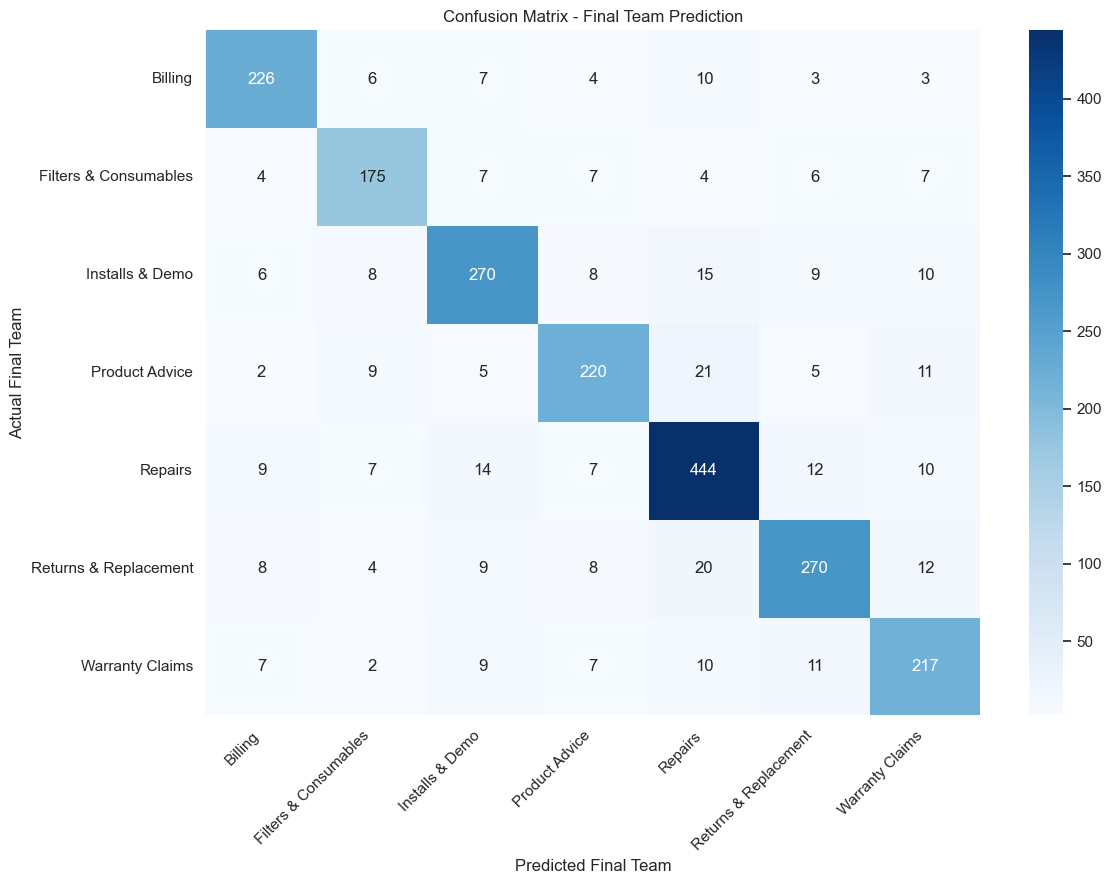

In [106]:
from sklearn.metrics import confusion_matrix

final_labels = final_team_model.named_steps[
    "classifier"
].classes_

final_cm = confusion_matrix(
    y_final_valid,
    y_final_pred,
    labels=final_labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_labels,
    yticklabels=final_labels
)

plt.title("Confusion Matrix - Final Team Prediction")
plt.xlabel("Predicted Final Team")
plt.ylabel("Actual Final Team")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [107]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_final_valid,
        y_final_pred,
        labels=final_labels,
        zero_division=0
    )
)

final_performance = pd.DataFrame({
    "Team": final_labels,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Support": support
})

display(
    final_performance.sort_values(
        "F1 Score",
        ascending=True
    )
)

,Team,Precision,Recall,F1 Score,Support
6,Warranty Claims,0.803704,0.825095,0.814259,263
3,Product Advice,0.842912,0.805861,0.823970,273
1,Filters & Consumables,0.829384,0.833333,0.831354,210
2,Installs & Demo,0.841121,0.828221,0.834621,326
5,Returns & Replacement,0.854430,0.815710,0.834621,331
4,Repairs,0.847328,0.882704,0.864654,503
0,Billing,0.862595,0.872587,0.867562,259


In [108]:
final_errors = X_final_valid.copy()

final_errors["Actual Final Team"] = y_final_valid
final_errors["Predicted Final Team"] = y_final_pred

final_errors["Correct"] = (
    final_errors["Actual Final Team"]
    == final_errors["Predicted Final Team"]
)

incorrect_final_predictions = final_errors[
    final_errors["Correct"] == False
].copy()

print("Total Validation Records:", len(final_errors))
print("Correct Predictions:", final_errors["Correct"].sum())
print("Incorrect Predictions:", len(incorrect_final_predictions))

display(
    incorrect_final_predictions[
        [
            "request_text",
            "channel",
            "product_family",
            "warranty_status",
            "Actual Final Team",
            "Predicted Final Team"
        ]
    ].head(25)
)

Total Validation Records: 2165
Correct Predictions: 1822
Incorrect Predictions: 343


,request_text,channel,product_family,warranty_status,Actual Final Team,Predicted Final Team
8658,not happy with fryer,ivr,Robot Vacuum,out_of_warranty,Returns & Replacement,Repairs
8670,"hi, help mixer grinder pls call back",whatsapp,Mixer Grinder,out_of_warranty,Returns & Replacement,Repairs
8673,"namaste, issue with induction cooktop order KO...",chat,Induction Cooktop,out_of_warranty,Filters & Consumables,Billing
8679,sir service request for product order KO2602707,whatsapp,Air Fryer,in_warranty,Returns & Replacement,Repairs
8689,issue with mixer grinder order KO2603933 pls c...,ivr,Mixer Grinder,in_warranty,Returns & Replacement,Repairs
8691,need help with my room heater reg no SR69239,whatsapp,Room Heater,out_of_warranty,Installs & Demo,Product Advice
8701,someone contact me about induction cooktop thanks,email,Induction Cooktop,in_warranty,Repairs,Product Advice
8705,"good morning, received used purifier, want exc...",ivr,Induction Cooktop,out_of_warranty,Product Advice,Returns & Replacement
8706,"hello team, box was open, purifier scratched, ...",whatsapp,Induction Cooktop,shield,Warranty Claims,Returns & Replacement
8716,"namaste, not happy with robot vacuum pls call ...",chat,Robot Vacuum,in_warranty,Installs & Demo,Product Advice


In [109]:
final_routing_errors = (
    incorrect_final_predictions
    .groupby([
        "Actual Final Team",
        "Predicted Final Team"
    ])
    .size()
    .reset_index(name="Error Count")
    .sort_values(
        "Error Count",
        ascending=False
    )
)

display(final_routing_errors.head(15))

,Actual Final Team,Predicted Final Team,Error Count
21,Product Advice,Repairs,21
34,Returns & Replacement,Repairs,20
15,Installs & Demo,Repairs,15
26,Repairs,Installs & Demo,14
35,Returns & Replacement,Warranty Claims,12
28,Repairs,Returns & Replacement,12
41,Warranty Claims,Returns & Replacement,11
23,Product Advice,Warranty Claims,11
3,Billing,Repairs,10
40,Warranty Claims,Repairs,10


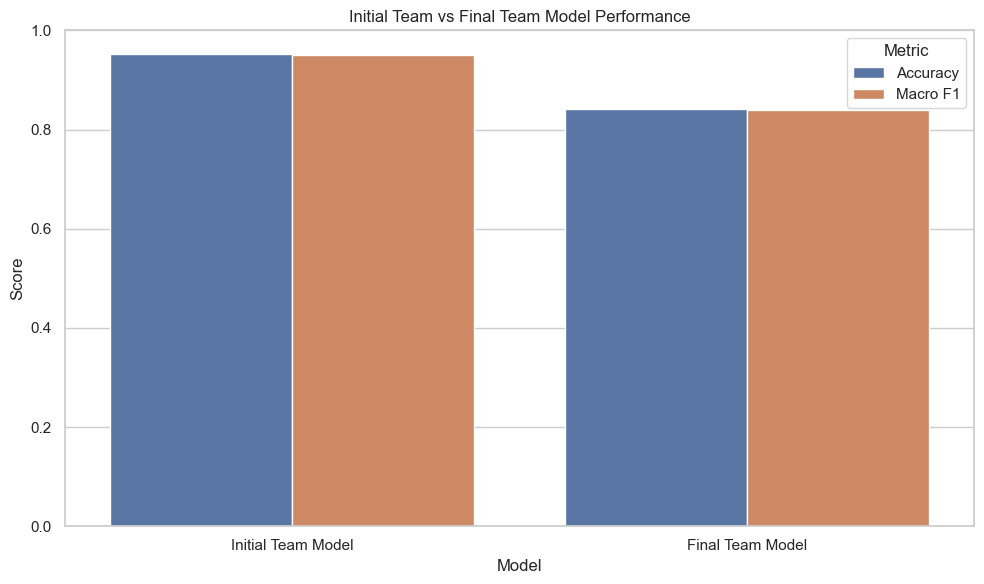

In [110]:
comparison_plot = pd.DataFrame({
    "Model": [
        "Initial Team Model",
        "Final Team Model"
    ],
    "Accuracy": [
        tuned_accuracy,
        final_accuracy
    ],
    "Macro F1": [
        tuned_macro_f1,
        final_macro_f1
    ]
})

comparison_plot_melted = comparison_plot.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Initial Team vs Final Team Model Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [111]:
import numpy as np
import pandas as pd

# Get decision scores from tuned initial-team model
decision_scores = grid_search.best_estimator_.decision_function(
    X_valid
)

# Sort decision scores for each request
sorted_scores = np.sort(
    decision_scores,
    axis=1
)

# Calculate difference between top two scores
confidence_margin = (
    sorted_scores[:, -1] - sorted_scores[:, -2]
)

# Create prediction analysis DataFrame
routing_analysis = X_valid.copy()

routing_analysis["Actual_Team"] = y_valid.values

routing_analysis["Predicted_Team"] = (
    y_pred_tuned
)

routing_analysis["Confidence_Margin"] = (
    confidence_margin
)

routing_analysis["Correct"] = (
    routing_analysis["Actual_Team"]
    == routing_analysis["Predicted_Team"]
)

print("Confidence Analysis Completed!")

display(
    routing_analysis[
        [
            "request_text",
            "Actual_Team",
            "Predicted_Team",
            "Confidence_Margin",
            "Correct"
        ]
    ].head(10)
)

Confidence Analysis Completed!


,request_text,Actual_Team,Predicted_Team,Confidence_Margin,Correct
8657,water purifier not working after 3 months very...,Filters & Consumables,Filters & Consumables,2.421189,True
8658,not happy with fryer,Repairs,Repairs,3.620159,True
8659,pls help - installation slot for air fryer not...,Installs & Demo,Installs & Demo,2.204691,True
8660,"good morning, charged twice for my ceiling fan...",Billing,Billing,1.760128,True
8661,is mixer safe for kids thanks,Product Advice,Product Advice,1.850867,True
8662,"hello team, extend warranty for water purifier",Warranty Claims,Warranty Claims,2.011129,True
8663,"good morning, warranty card for air fryer not ...",Warranty Claims,Warranty Claims,1.850670,True
8664,"namaste, coupon discount not applied on robot ...",Billing,Billing,1.493709,True
8665,"hi, return pickup for air fryer not done order...",Returns & Replacement,Returns & Replacement,2.019549,True
8666,installer did not turn up for ceiling fan asap,Installs & Demo,Installs & Demo,1.982453,True


In [112]:
thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30
]

threshold_results = []

for threshold in thresholds:

    # Requests above threshold
    auto_mask = (
        routing_analysis["Confidence_Margin"]
        >= threshold
    )

    auto_requests = routing_analysis[
        auto_mask
    ]

    review_requests = routing_analysis[
        ~auto_mask
    ]

    if len(auto_requests) > 0:
        auto_accuracy = auto_requests["Correct"].mean()
    else:
        auto_accuracy = np.nan

    coverage = (
        len(auto_requests)
        / len(routing_analysis)
    )

    threshold_results.append({
        "Threshold": threshold,
        "Auto_Routed": len(auto_requests),
        "Human_Review": len(review_requests),
        "Auto_Routing_Coverage": coverage,
        "Auto_Routing_Accuracy": auto_accuracy
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_results_df.round(4)
)

,Threshold,Auto_Routed,Human_Review,Auto_Routing_Coverage,Auto_Routing_Accuracy
0,0.05,2147,18,0.9917,0.9576
1,0.10,2144,21,0.9903,0.9580
2,0.15,2134,31,0.9857,0.9588
3,0.20,2126,39,0.9820,0.9600
4,0.25,2116,49,0.9774,0.9617
5,0.30,2103,62,0.9714,0.9658


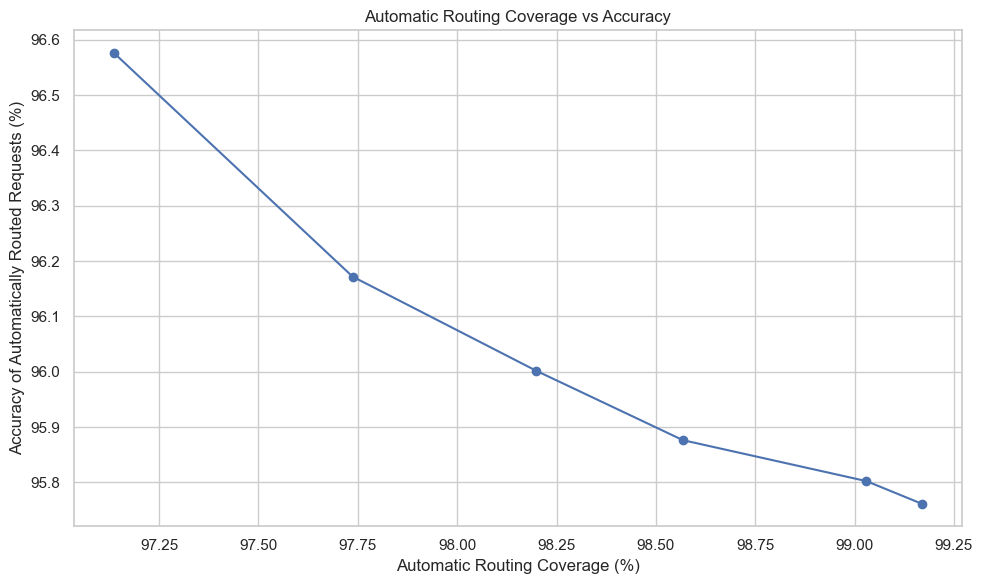

In [113]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results_df["Auto_Routing_Coverage"] * 100,
    threshold_results_df["Auto_Routing_Accuracy"] * 100,
    marker="o"
)

plt.title(
    "Automatic Routing Coverage vs Accuracy"
)

plt.xlabel("Automatic Routing Coverage (%)")

plt.ylabel("Accuracy of Automatically Routed Requests (%)")

plt.grid(True)

plt.tight_layout()

plt.show()

In [114]:
REVIEW_THRESHOLD = 0.20

routing_analysis["Routing_Status"] = np.where(
    routing_analysis["Confidence_Margin"]
    >= REVIEW_THRESHOLD,
    "Automatic Routing",
    "Human Review"
)

print("Routing Status Distribution:")

display(
    routing_analysis["Routing_Status"]
    .value_counts()
)

print("\nRouting Status Percentages:")

display(
    routing_analysis["Routing_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Routing Status Distribution:


Routing_Status
Automatic Routing    2126
Human Review           39
Name: count, dtype: int64


Routing Status Percentages:


Routing_Status
Automatic Routing    98.2
Human Review          1.8
Name: proportion, dtype: float64

In [115]:
human_review_queue = routing_analysis[
    routing_analysis["Routing_Status"]
    == "Human Review"
].copy()

human_review_queue = human_review_queue.sort_values(
    "Confidence_Margin",
    ascending=True
)

human_review_queue = human_review_queue[
    [
        "request_text",
        "channel",
        "product_family",
        "warranty_status",
        "Predicted_Team",
        "Actual_Team",
        "Confidence_Margin"
    ]
]

print(
    "Total Requests for Human Review:",
    len(human_review_queue)
)

display(
    human_review_queue.head(20)
)

Total Requests for Human Review: 39


,request_text,channel,product_family,warranty_status,Predicted_Team,Actual_Team,Confidence_Margin
9174,urgent: invoice not received for water purifie...,chat,Water Purifier,in_warranty,Warranty Claims,Warranty Claims,0.000119
9716,"namaste, filter change reminder for induction ...",chat,Induction Cooktop,in_warranty,Filters & Consumables,Repairs,0.003210
10243,urgent: claim status for water purifier under ...,whatsapp,Water Purifier,in_warranty,Returns & Replacement,Returns & Replacement,0.003972
10157,"good morning, water purifier showing error cod...",ivr,Water Purifier,shield,Filters & Consumables,Filters & Consumables,0.007544
10639,"hi, product missing parts in box, need help wi...",ivr,Mixer Grinder,in_warranty,Repairs,Repairs,0.011328
8802,"pls help - box was open, fan scratched, fan qu...",ivr,Room Heater,out_of_warranty,Returns & Replacement,Repairs,0.015208
9600,"hello team, need warranty certificate ceiling ...",whatsapp,Ceiling Fan,in_warranty,Repairs,Repairs,0.018675
10090,"urgent: how to clean air fryer, want AMC filte...",chat,Air Fryer,out_of_warranty,Product Advice,Filters & Consumables,0.023895
10428,"namaste, wall mounting for robot vacuum pendin...",whatsapp,Robot Vacuum,in_warranty,Installs & Demo,Repairs,0.028467
8987,"hello team, water purifier leaking water from ...",email,Water Purifier,shield,Filters & Consumables,Filters & Consumables,0.028486


In [116]:
auto_routed = routing_analysis[
    routing_analysis["Routing_Status"]
    == "Automatic Routing"
]

human_review = routing_analysis[
    routing_analysis["Routing_Status"]
    == "Human Review"
]

print("=" * 55)
print("ROUTING SYSTEM EVALUATION")
print("=" * 55)

print(
    "Total Requests:",
    len(routing_analysis)
)

print(
    "Automatically Routed:",
    len(auto_routed)
)

print(
    "Sent for Human Review:",
    len(human_review)
)

if len(auto_routed) > 0:

    print(
        "Automatic Routing Accuracy:",
        round(
            auto_routed["Correct"].mean() * 100,
            2
        ),
        "%"
    )

print(
    "Human Review Percentage:",
    round(
        len(human_review)
        / len(routing_analysis) * 100,
        2
    ),
    "%"
)

ROUTING SYSTEM EVALUATION
Total Requests: 2165
Automatically Routed: 2126
Sent for Human Review: 39
Automatic Routing Accuracy: 96.0 %
Human Review Percentage: 1.8 %


In [117]:
import re

routing_rules = {
    "Repairs": [
        r"\bnot working\b",
        r"\bstopped working\b",
        r"\bproduct fault\b",
        r"\bburnt smell\b",
        r"\bloud noise\b",
        r"\berror code\b",
        r"\bmotor problem\b",
        r"\bleaking water\b",
        r"\bdisplay gone blank\b",
        r"\bmachine breakdown\b"
    ],

    "Installs & Demo": [
        r"\binstallation\b",
        r"\binstall\b",
        r"\binstaller\b",
        r"\bwall mounting\b",
        r"\bwall mount\b",
        r"\bdemo\b",
        r"\binstallation slot\b",
        r"\btechnician visit\b"
    ],

    "Billing": [
        r"\binvoice\b",
        r"\bgst\b",
        r"\bcharged twice\b",
        r"\bdouble charge\b",
        r"\bpayment deducted\b",
        r"\brefund\b",
        r"\bemi\b",
        r"\bcoupon discount\b",
        r"\bpayment failed\b"
    ],

    "Returns & Replacement": [
        r"\bdamaged\b",
        r"\bscratched\b",
        r"\bwrong item\b",
        r"\bmissing parts\b",
        r"\bbox was open\b",
        r"\breturn pickup\b",
        r"\breplacement\b",
        r"\bexchange\b"
    ],

    "Warranty Claims": [
        r"\bwarranty claim\b",
        r"\bwarranty card\b",
        r"\bwarranty registration\b",
        r"\bwarranty certificate\b",
        r"\bwarranty rejected\b",
        r"\bkestrel shield\b",
        r"\bclaim status\b"
    ],

    "Filters & Consumables": [
        r"\bfilter change\b",
        r"\bfilter replacement\b",
        r"\bconsumable pack\b",
        r"\bcandle\b",
        r"\bmembrane\b",
        r"\bspare blade\b",
        r"\bspare brush\b",
        r"\bjar available\b"
    ],

    "Product Advice": [
        r"\bbest settings\b",
        r"\bsafe for kids\b",
        r"\bhow to clean\b",
        r"\brecipe booklet\b",
        r"\bdifference between\b",
        r"\bcan .* run on inverter\b",
        r"\bhow to use\b"
    ]
}

print("Business routing rules created.")

for team, patterns in routing_rules.items():
    print(team, ":", len(patterns), "rules")

Business routing rules created.
Repairs : 10 rules
Installs & Demo : 8 rules
Billing : 9 rules
Returns & Replacement : 8 rules
Warranty Claims : 7 rules
Filters & Consumables : 8 rules
Product Advice : 7 rules


In [118]:
def detect_routing_rules(request_text):

    text = str(request_text).lower()

    matched_teams = []

    for team, patterns in routing_rules.items():

        for pattern in patterns:

            if re.search(pattern, text):

                matched_teams.append(team)
                break

    if len(matched_teams) == 0:

        return {
            "Rule_Team": None,
            "Rule_Status": "No Rule Match",
            "Matched_Teams": []
        }

    elif len(matched_teams) == 1:

        return {
            "Rule_Team": matched_teams[0],
            "Rule_Status": "Single Rule Match",
            "Matched_Teams": matched_teams
        }

    else:

        return {
            "Rule_Team": None,
            "Rule_Status": "Multiple Rule Matches",
            "Matched_Teams": matched_teams
        }

In [119]:
sample_requests = [
    "water purifier showing error code E3",
    "please send technician for installation",
    "charged twice for my air fryer",
    "received damaged product need replacement",
    "warranty card not registered",
    "need replacement filter for purifier",
    "how to clean robot vacuum",
    "product not working and need warranty claim"
]

sample_rule_results = []

for request in sample_requests:

    result = detect_routing_rules(request)

    sample_rule_results.append({
        "Request": request,
        "Rule Team": result["Rule_Team"],
        "Rule Status": result["Rule_Status"],
        "Matched Teams": result["Matched_Teams"]
    })

display(pd.DataFrame(sample_rule_results))

,Request,Rule Team,Rule Status,Matched Teams
0,water purifier showing error code E3,Repairs,Single Rule Match,[Repairs]
1,please send technician for installation,Installs & Demo,Single Rule Match,[Installs & Demo]
2,charged twice for my air fryer,Billing,Single Rule Match,[Billing]
3,received damaged product need replacement,Returns & Replacement,Single Rule Match,[Returns & Replacement]
4,warranty card not registered,Warranty Claims,Single Rule Match,[Warranty Claims]
5,need replacement filter for purifier,Returns & Replacement,Single Rule Match,[Returns & Replacement]
6,how to clean robot vacuum,Product Advice,Single Rule Match,[Product Advice]
7,product not working and need warranty claim,None,Multiple Rule Matches,"[Repairs, Warranty Claims]"


In [120]:
rule_validation = X_valid.copy()

rule_validation["Actual_Team"] = y_valid.values

rule_validation["ML_Prediction"] = (
    y_pred_tuned
)

rule_validation["Confidence_Margin"] = (
    confidence_margin
)

rule_results = rule_validation["request_text"].apply(
    detect_routing_rules
)

rule_validation["Rule_Team"] = rule_results.apply(
    lambda x: x["Rule_Team"]
)

rule_validation["Rule_Status"] = rule_results.apply(
    lambda x: x["Rule_Status"]
)

rule_validation["Matched_Teams"] = rule_results.apply(
    lambda x: ", ".join(x["Matched_Teams"])
)

display(
    rule_validation[
        [
            "request_text",
            "Actual_Team",
            "ML_Prediction",
            "Rule_Team",
            "Rule_Status",
            "Confidence_Margin"
        ]
    ].head(20)
)

,request_text,Actual_Team,ML_Prediction,Rule_Team,Rule_Status,Confidence_Margin
8657,water purifier not working after 3 months very...,Filters & Consumables,Filters & Consumables,Repairs,Single Rule Match,2.421189
8658,not happy with fryer,Repairs,Repairs,None,No Rule Match,3.620159
8659,pls help - installation slot for air fryer not...,Installs & Demo,Installs & Demo,Installs & Demo,Single Rule Match,2.204691
8660,"good morning, charged twice for my ceiling fan...",Billing,Billing,Billing,Single Rule Match,1.760128
8661,is mixer safe for kids thanks,Product Advice,Product Advice,Product Advice,Single Rule Match,1.850867
8662,"hello team, extend warranty for water purifier",Warranty Claims,Warranty Claims,None,No Rule Match,2.011129
8663,"good morning, warranty card for air fryer not ...",Warranty Claims,Warranty Claims,Warranty Claims,Single Rule Match,1.850670
8664,"namaste, coupon discount not applied on robot ...",Billing,Billing,Billing,Single Rule Match,1.493709
8665,"hi, return pickup for air fryer not done order...",Returns & Replacement,Returns & Replacement,Returns & Replacement,Single Rule Match,2.019549
8666,installer did not turn up for ceiling fan asap,Installs & Demo,Installs & Demo,Installs & Demo,Single Rule Match,1.982453


In [121]:
print("Business Rule Status Distribution")

display(
    rule_validation["Rule_Status"]
    .value_counts()
)

print("\nBusiness Rule Coverage Percentage")

display(
    (
        rule_validation["Rule_Status"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

Business Rule Status Distribution


Rule_Status
Single Rule Match        1325
No Rule Match             760
Multiple Rule Matches      80
Name: count, dtype: int64


Business Rule Coverage Percentage


Rule_Status
Single Rule Match        61.2
No Rule Match            35.1
Multiple Rule Matches     3.7
Name: proportion, dtype: float64

In [122]:
single_rule_data = rule_validation[
    rule_validation["Rule_Status"]
    == "Single Rule Match"
].copy()

single_rule_data["Rule_Correct"] = (
    single_rule_data["Rule_Team"]
    == single_rule_data["Actual_Team"]
)

print("Total Single Rule Matches:", len(single_rule_data))

if len(single_rule_data) > 0:

    print(
        "Business Rule Accuracy:",
        round(
            single_rule_data["Rule_Correct"].mean() * 100,
            2
        ),
        "%"
    )

    print(
        "Correct Rule Predictions:",
        single_rule_data["Rule_Correct"].sum()
    )

    print(
        "Incorrect Rule Predictions:",
        (~single_rule_data["Rule_Correct"]).sum()
    )

Total Single Rule Matches: 1325
Business Rule Accuracy: 84.98 %
Correct Rule Predictions: 1126
Incorrect Rule Predictions: 199


In [123]:
rule_conflicts = single_rule_data[
    single_rule_data["ML_Prediction"]
    != single_rule_data["Rule_Team"]
].copy()

print("ML and Business Rule Conflicts:", len(rule_conflicts))

display(
    rule_conflicts[
        [
            "request_text",
            "Actual_Team",
            "ML_Prediction",
            "Rule_Team",
            "Confidence_Margin",
            "Rule_Correct"
        ]
    ].head(30)
)

ML and Business Rule Conflicts: 156


,request_text,Actual_Team,ML_Prediction,Rule_Team,Confidence_Margin,Rule_Correct
8657,water purifier not working after 3 months very...,Filters & Consumables,Filters & Consumables,Repairs,2.421189,False
8681,"hi, warranty claim for room heater bought 9 mo...",Billing,Billing,Warranty Claims,1.705703,False
8687,need replacement filter for induction cooktop ...,Filters & Consumables,Filters & Consumables,Returns & Replacement,2.632104,False
8706,"hello team, box was open, purifier scratched, ...",Repairs,Repairs,Returns & Replacement,1.190654,False
8723,water purifier leaking water from bottom reg n...,Repairs,Filters & Consumables,Repairs,3.159413,True
8759,water purifier not working after 8 months orde...,Filters & Consumables,Filters & Consumables,Repairs,2.620577,False
8789,sir motor of vacuum burnt smell i paid extra f...,Billing,Billing,Repairs,1.378860,False
8795,"hello team, motor of water purifier burnt smel...",Filters & Consumables,Filters & Consumables,Repairs,0.568058,False
8835,need installation for my new purifier already ...,Billing,Billing,Installs & Demo,1.797755,False
8838,purifier stopped working after 9 months very d...,Filters & Consumables,Filters & Consumables,Repairs,0.831753,False


In [124]:
rule_validation["Combined_Prediction"] = (
    rule_validation["ML_Prediction"]
)

single_match_mask = (
    rule_validation["Rule_Status"]
    == "Single Rule Match"
)

rule_validation.loc[
    single_match_mask,
    "Combined_Prediction"
] = rule_validation.loc[
    single_match_mask,
    "Rule_Team"
]

ml_accuracy = accuracy_score(
    rule_validation["Actual_Team"],
    rule_validation["ML_Prediction"]
)

combined_accuracy = accuracy_score(
    rule_validation["Actual_Team"],
    rule_validation["Combined_Prediction"]
)

print("ML Model Accuracy:", round(ml_accuracy * 100, 2), "%")

print(
    "ML + Business Rules Accuracy:",
    round(combined_accuracy * 100, 2),
    "%"
)

ML Model Accuracy: 95.29 %
ML + Business Rules Accuracy: 89.33 %


In [125]:
# Create a copy of validation results
hybrid_routing = rule_validation.copy()

# Preserve original ML prediction
hybrid_routing["Final_Prediction"] = (
    hybrid_routing["ML_Prediction"]
)

# Identify low-confidence predictions
low_confidence = (
    hybrid_routing["Confidence_Margin"] < 0.20
)

# Identify multiple rule matches
multiple_rules = (
    hybrid_routing["Rule_Status"]
    == "Multiple Rule Matches"
)

# Identify conflicts between ML and single business rule
rule_conflict = (
    (hybrid_routing["Rule_Status"] == "Single Rule Match")
    &
    (hybrid_routing["ML_Prediction"] != hybrid_routing["Rule_Team"])
)

# Create review reasons
hybrid_routing["Review_Reason"] = np.select(
    [
        low_confidence,
        multiple_rules,
        rule_conflict
    ],
    [
        "Low Confidence",
        "Multiple Business Rules",
        "ML and Business Rule Conflict"
    ],
    default="No Review Required"
)

# Assign routing status
hybrid_routing["Routing_Status"] = np.where(
    hybrid_routing["Review_Reason"] == "No Review Required",
    "Automatic Routing",
    "Human Review"
)

print("Hybrid Routing System Created!")

display(
    hybrid_routing[
        [
            "request_text",
            "ML_Prediction",
            "Rule_Team",
            "Confidence_Margin",
            "Routing_Status",
            "Review_Reason"
        ]
    ].head(20)
)

Hybrid Routing System Created!


,request_text,ML_Prediction,Rule_Team,Confidence_Margin,Routing_Status,Review_Reason
8657,water purifier not working after 3 months very...,Filters & Consumables,Repairs,2.421189,Human Review,ML and Business Rule Conflict
8658,not happy with fryer,Repairs,None,3.620159,Automatic Routing,No Review Required
8659,pls help - installation slot for air fryer not...,Installs & Demo,Installs & Demo,2.204691,Automatic Routing,No Review Required
8660,"good morning, charged twice for my ceiling fan...",Billing,Billing,1.760128,Automatic Routing,No Review Required
8661,is mixer safe for kids thanks,Product Advice,Product Advice,1.850867,Automatic Routing,No Review Required
8662,"hello team, extend warranty for water purifier",Warranty Claims,None,2.011129,Automatic Routing,No Review Required
8663,"good morning, warranty card for air fryer not ...",Warranty Claims,Warranty Claims,1.850670,Automatic Routing,No Review Required
8664,"namaste, coupon discount not applied on robot ...",Billing,Billing,1.493709,Automatic Routing,No Review Required
8665,"hi, return pickup for air fryer not done order...",Returns & Replacement,Returns & Replacement,2.019549,Automatic Routing,No Review Required
8666,installer did not turn up for ceiling fan asap,Installs & Demo,Installs & Demo,1.982453,Automatic Routing,No Review Required


In [126]:
print("Routing Status Distribution")

display(
    hybrid_routing["Routing_Status"]
    .value_counts()
)

print("\nReview Reason Distribution")

display(
    hybrid_routing["Review_Reason"]
    .value_counts()
)

Routing Status Distribution


Routing_Status
Automatic Routing    1915
Human Review          250
Name: count, dtype: int64


Review Reason Distribution


Review_Reason
No Review Required               1915
ML and Business Rule Conflict     144
Multiple Business Rules            67
Low Confidence                     39
Name: count, dtype: int64

In [127]:
automatic_requests = hybrid_routing[
    hybrid_routing["Routing_Status"]
    == "Automatic Routing"
]

human_review_requests = hybrid_routing[
    hybrid_routing["Routing_Status"]
    == "Human Review"
]

if len(automatic_requests) > 0:

    automatic_accuracy = accuracy_score(
        automatic_requests["Actual_Team"],
        automatic_requests["Final_Prediction"]
    )

else:
    automatic_accuracy = np.nan

print("=" * 50)
print("HYBRID ROUTING PERFORMANCE")
print("=" * 50)

print("Total Requests:", len(hybrid_routing))

print(
    "Automatic Routing:",
    len(automatic_requests)
)

print(
    "Human Review:",
    len(human_review_requests)
)

print(
    "Automatic Routing Coverage:",
    round(
        len(automatic_requests)
        / len(hybrid_routing) * 100,
        2
    ),
    "%"
)

print(
    "Automatic Routing Accuracy:",
    round(automatic_accuracy * 100, 2),
    "%"
)

HYBRID ROUTING PERFORMANCE
Total Requests: 2165
Automatic Routing: 1915
Human Review: 250
Automatic Routing Coverage: 88.45 %
Automatic Routing Accuracy: 96.92 %


In [128]:
strategy_comparison = pd.DataFrame({
    "Strategy": [
        "ML Only",
        "ML + Business Rule Override",
        "ML + Human Review"
    ],

    "Accuracy": [
        accuracy_score(
            rule_validation["Actual_Team"],
            rule_validation["ML_Prediction"]
        ),

        accuracy_score(
            rule_validation["Actual_Team"],
            rule_validation["Combined_Prediction"]
        ),

        automatic_accuracy
    ],

    "Requests Automatically Routed": [
        len(rule_validation),

        len(rule_validation),

        len(automatic_requests)
    ],

    "Requests Sent for Review": [
        0,
        0,
        len(human_review_requests)
    ]
})

display(strategy_comparison.round(4))

,Strategy,Accuracy,Requests Automatically Routed,Requests Sent for Review
0,ML Only,0.9529,2165,0
1,ML + Business Rule Override,0.8933,2165,0
2,ML + Human Review,0.9692,1915,250


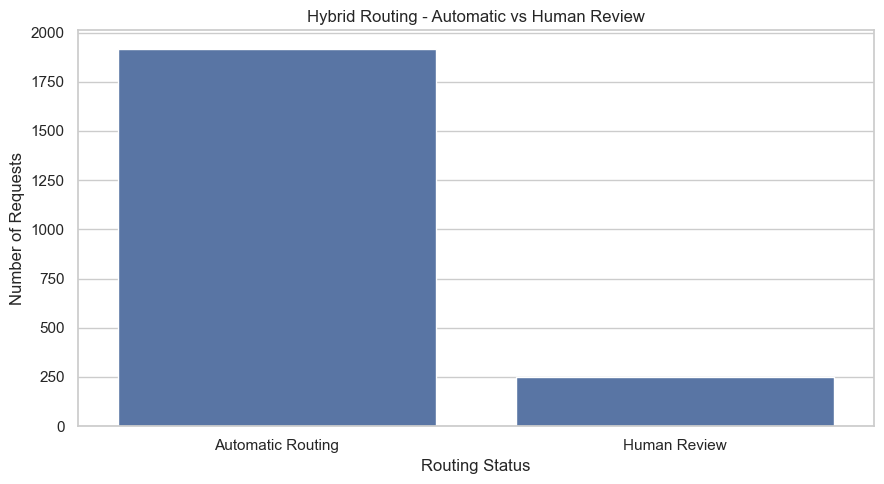

In [129]:
status_counts = (
    hybrid_routing["Routing_Status"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Hybrid Routing - Automatic vs Human Review")

plt.xlabel("Routing Status")
plt.ylabel("Number of Requests")

plt.tight_layout()
plt.show()

In [130]:
review_export = hybrid_routing[
    hybrid_routing["Routing_Status"] == "Human Review"
][
    [
        "request_text",
        "channel",
        "product_family",
        "warranty_status",
        "ML_Prediction",
        "Rule_Team",
        "Confidence_Margin",
        "Review_Reason"
    ]
].copy()

review_export.to_csv(
    "human_review_queue.csv",
    index=False
)

print("Human Review Queue Exported Successfully!")
print("Records:", len(review_export))

Human Review Queue Exported Successfully!
Records: 250


In [131]:
# Select the final model features

X_train_full = train_clean[
    feature_columns
].copy()

y_train_full = train_clean[
    "team_label"
].copy()

X_test_final = test_clean[
    feature_columns
].copy()

print("Final Training Features:", X_train_full.shape)
print("Final Training Target:", y_train_full.shape)
print("Final Testing Features:", X_test_final.shape)

print("\nTraining Target Distribution:")
display(y_train_full.value_counts())

Final Training Features: (10822, 11)
Final Training Target: (10822,)
Final Testing Features: (2178, 11)

Training Target Distribution:


team_label
Repairs                  3129
Billing                  1656
Filters & Consumables    1458
Installs & Demo          1185
Product Advice           1180
Returns & Replacement    1174
Warranty Claims          1040
Name: count, dtype: int64

In [132]:
from sklearn.base import clone
import time

# Get best tuned pipeline
final_model = clone(
    grid_search.best_estimator_
)

# Train using all labelled records
start_time = time.time()

final_model.fit(
    X_train_full,
    y_train_full
)

training_time = time.time() - start_time

print("Final Model Training Completed!")

print(
    "Training Time:",
    round(training_time, 2),
    "seconds"
)

print("\nSelected Hyperparameters:")
print(grid_search.best_params_)

Final Model Training Completed!
Training Time: 1.06 seconds

Selected Hyperparameters:
{'classifier__C': 1.5, 'classifier__class_weight': None}


In [133]:
# Predict service teams for test requests

test_predictions = final_model.predict(
    X_test_final
)

print("Test Predictions Generated!")

print(
    "Total Predictions:",
    len(test_predictions)
)

print("\nPredicted Team Distribution:")

display(
    pd.Series(
        test_predictions,
        name="Predicted_Team"
    ).value_counts()
)

Test Predictions Generated!
Total Predictions: 2178

Predicted Team Distribution:


Predicted_Team
Repairs                  648
Billing                  334
Filters & Consumables    280
Installs & Demo          243
Returns & Replacement    241
Product Advice           231
Warranty Claims          201
Name: count, dtype: int64

In [134]:
# Calculate decision scores
test_decision_scores = final_model.decision_function(
    X_test_final
)

# Sort scores
test_sorted_scores = np.sort(
    test_decision_scores,
    axis=1
)

# Calculate top-two decision score margin
test_confidence_margin = (
    test_sorted_scores[:, -1]
    - test_sorted_scores[:, -2]
)

print("Confidence Scores Generated!")

Confidence Scores Generated!


In [136]:
# Create final production prediction DataFrame

production_predictions = pd.DataFrame({
    "request_id": test_clean["request_id"].values,
    "team": test_predictions,
    "confidence_margin": test_confidence_margin
})

# Apply business routing rules
rule_results = test_clean["request_text"].apply(
    detect_routing_rules
)

production_predictions["Rule_Team"] = rule_results.apply(
    lambda x: x["Rule_Team"]
).values

production_predictions["Rule_Status"] = rule_results.apply(
    lambda x: x["Rule_Status"]
).values

# Identify low-confidence predictions
low_confidence_mask = (
    production_predictions["confidence_margin"] < 0.20
)

# Identify multiple business rule matches
multiple_rule_mask = (
    production_predictions["Rule_Status"]
    == "Multiple Rule Matches"
)

# Identify ML and business rule conflicts
rule_conflict_mask = (
    (production_predictions["Rule_Status"] == "Single Rule Match")
    &
    (production_predictions["team"]
     != production_predictions["Rule_Team"])
)

# Determine routing status
review_mask = (
    low_confidence_mask
    | multiple_rule_mask
    | rule_conflict_mask
)

production_predictions["routing_status"] = np.where(
    review_mask,
    "Human Review",
    "Automatic Routing"
)

print("Production Routing Predictions Generated!")

display(production_predictions.head(15))

Production Routing Predictions Generated!


,request_id,team,confidence_margin,Rule_Team,Rule_Status,routing_status
0,SR510822,Repairs,1.992565,None,No Rule Match,Automatic Routing
1,SR510823,Filters & Consumables,1.533079,None,No Rule Match,Automatic Routing
2,SR510824,Filters & Consumables,2.679758,Repairs,Single Rule Match,Human Review
3,SR510825,Billing,1.559248,Installs & Demo,Single Rule Match,Human Review
4,SR510826,Installs & Demo,1.627286,Installs & Demo,Single Rule Match,Automatic Routing
5,SR510827,Installs & Demo,2.185830,Installs & Demo,Single Rule Match,Automatic Routing
6,SR510828,Installs & Demo,2.436642,Installs & Demo,Single Rule Match,Automatic Routing
7,SR510829,Installs & Demo,1.482093,Installs & Demo,Single Rule Match,Automatic Routing
8,SR510830,Installs & Demo,2.133532,Installs & Demo,Single Rule Match,Automatic Routing
9,SR510831,Repairs,2.050851,None,No Rule Match,Automatic Routing


In [137]:
# Create submission with required columns
submission = production_predictions[
    ["request_id", "team"]
].copy()

# Preserve sample submission ordering
submission = sample_submission_df[
    ["request_id"]
].merge(
    submission,
    on="request_id",
    how="left",
    validate="one_to_one"
)

# Validate output
assert submission["request_id"].is_unique
assert submission["team"].notna().all()
assert len(submission) == len(test_clean)

# Save CSV
submission.to_csv(
    "predictions.csv",
    index=False
)

print("Final predictions.csv created successfully!")

print("Submission Shape:", submission.shape)

display(submission.head(10))

Final predictions.csv created successfully!
Submission Shape: (2178, 2)


,request_id,team
0,SR510822,Repairs
1,SR510823,Filters & Consumables
2,SR510824,Filters & Consumables
3,SR510825,Billing
4,SR510826,Installs & Demo
5,SR510827,Installs & Demo
6,SR510828,Installs & Demo
7,SR510829,Installs & Demo
8,SR510830,Installs & Demo
9,SR510831,Repairs


In [138]:
production_review_queue = production_predictions[
    production_predictions["routing_status"]
    == "Human Review"
].copy()

production_review_queue.to_csv(
    "production_human_review_queue.csv",
    index=False
)

print(
    "Production Human Review Records:",
    len(production_review_queue)
)

print(
    "Production Automatic Routing Records:",
    (production_predictions["routing_status"]
     == "Automatic Routing").sum()
)

Production Human Review Records: 235
Production Automatic Routing Records: 1943


In [139]:
print("=" * 55)
print("FINAL PRODUCTION PIPELINE VALIDATION")
print("=" * 55)

print("Training Records:", len(X_train_full))
print("Testing Records:", len(X_test_final))

print(
    "Predictions Generated:",
    len(submission)
)

print(
    "Unique Request IDs:",
    submission["request_id"].nunique()
)

print(
    "Missing Predictions:",
    submission["team"].isna().sum()
)

print(
    "Human Review Requests:",
    len(production_review_queue)
)

print(
    "Automatic Routing Requests:",
    (production_predictions["routing_status"]
     == "Automatic Routing").sum()
)

assert len(submission) == 2178
assert submission["team"].notna().all()
assert submission["request_id"].is_unique

print("\nAll Production Validation Checks Passed!")

FINAL PRODUCTION PIPELINE VALIDATION
Training Records: 10822
Testing Records: 2178
Predictions Generated: 2178
Unique Request IDs: 2178
Missing Predictions: 0
Human Review Requests: 235
Automatic Routing Requests: 1943

All Production Validation Checks Passed!


In [140]:
# ==========================================
# STEP 20: EXPORT PRODUCTION ROUTING FILES
# ==========================================

import os
import pandas as pd

# Create output directory
os.makedirs("production_outputs", exist_ok=True)

# 1. Complete production predictions
production_predictions.to_csv(
    "production_outputs/production_predictions.csv",
    index=False
)

# 2. Automatic routing queue
automatic_queue = production_predictions[
    production_predictions["routing_status"] == "Automatic Routing"
].copy()

automatic_queue.to_csv(
    "production_outputs/automatic_routing_queue.csv",
    index=False
)

# 3. Human review queue
human_review_queue = production_predictions[
    production_predictions["routing_status"] == "Human Review"
].copy()

human_review_queue.to_csv(
    "production_outputs/human_review_queue.csv",
    index=False
)

# 4. Final submission file
submission = production_predictions[
    ["request_id", "team"]
].copy()

submission.to_csv(
    "production_outputs/predictions.csv",
    index=False
)

# 5. Production summary
production_summary = pd.DataFrame({
    "Metric": [
        "Total Requests",
        "Automatic Routing",
        "Human Review",
        "Automatic Routing Percentage",
        "Human Review Percentage",
        "Missing Predictions"
    ],
    "Value": [
        len(production_predictions),
        len(automatic_queue),
        len(human_review_queue),
        round(len(automatic_queue) / len(production_predictions) * 100, 2),
        round(len(human_review_queue) / len(production_predictions) * 100, 2),
        production_predictions["team"].isna().sum()
    ]
})

production_summary.to_csv(
    "production_outputs/production_summary.csv",
    index=False
)

print("Production Files Exported Successfully!")

print("\nAutomatic Routing Records:", len(automatic_queue))
print("Human Review Records:", len(human_review_queue))

display(production_summary)

Production Files Exported Successfully!

Automatic Routing Records: 1943
Human Review Records: 235


,Metric,Value
0,Total Requests,2178.00
1,Automatic Routing,1943.00
2,Human Review,235.00
3,Automatic Routing Percentage,89.21
4,Human Review Percentage,10.79
5,Missing Predictions,0.00


In [141]:
# ==========================================
# STEP 21: SAVE TRAINED MODEL
# ==========================================

import os
import joblib
import json

# Create model directory
os.makedirs("production_outputs/models", exist_ok=True)

# IMPORTANT:
# Replace final_model with the exact trained
# model/pipeline variable used to generate test_predictions.

production_model = final_model

# Save trained model
model_path = "production_outputs/models/kestrel_routing_model.pkl"

joblib.dump(production_model, model_path)

# Save model metadata
model_metadata = {
    "project": "Kestrel Home Service Request Routing",
    "model_type": type(production_model).__name__,
    "training_records": len(train_clean),
    "testing_records": len(test_clean),
    "number_of_teams": int(train_clean["team_label"].nunique()),
    "features": X_train.columns.tolist()
}

metadata_path = "production_outputs/models/model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(model_metadata, file, indent=4)

print("Model Saved Successfully!")
print("Model Path:", model_path)
print("Metadata Path:", metadata_path)

print("\nModel Information:")
print(json.dumps(model_metadata, indent=4))

Model Saved Successfully!
Model Path: production_outputs/models/kestrel_routing_model.pkl
Metadata Path: production_outputs/models/model_metadata.json

Model Information:
{
    "project": "Kestrel Home Service Request Routing",
    "model_type": "Pipeline",
    "training_records": 10822,
    "testing_records": 2178,
    "number_of_teams": 7,
    "features": [
        "request_text",
        "channel",
        "product_family",
        "warranty_status",
        "source",
        "time_period",
        "request_hour",
        "request_day",
        "request_month",
        "request_day_of_month",
        "is_weekend"
    ]
}


In [142]:
# ==========================================
# STEP 22: TEST SAVED MODEL WITH NEW REQUESTS
# ==========================================

import pandas as pd
import numpy as np
import joblib

# 1. Load saved production model
loaded_model = joblib.load(
    "production_outputs/models/kestrel_routing_model.pkl"
)

print("Saved Model Loaded Successfully!")

# 2. Create new customer service requests
new_requests = pd.DataFrame({
    "request_id": ["NEW001", "NEW002", "NEW003", "NEW004"],
    "created_at_ist": [
        "2026-11-26 10:30",
        "2026-11-26 14:15",
        "2026-11-26 16:45",
        "2026-11-26 19:20"
    ],
    "channel": ["whatsapp", "chat", "email", "ivr"],
    "product_family": [
        "Water Purifier",
        "Air Fryer",
        "Mixer Grinder",
        "Ceiling Fan"
    ],
    "warranty_status": [
        "in_warranty",
        "out_of_warranty",
        "shield",
        "in_warranty"
    ],
    "request_text": [
        "Water purifier showing error code E3 and not working",
        "Air fryer delivered damaged and need replacement",
        "Please send invoice for my mixer grinder",
        "Need technician for ceiling fan installation"
    ],
    "source": ["crm", "crm", "legacy_zoho", "crm"]
})

# 3. Convert timestamp
new_requests["created_at_ist"] = pd.to_datetime(
    new_requests["created_at_ist"]
)

# 4. Create date-time features
new_requests["request_hour"] = (
    new_requests["created_at_ist"].dt.hour
)

new_requests["request_day"] = (
    new_requests["created_at_ist"].dt.dayofweek
)

new_requests["request_month"] = (
    new_requests["created_at_ist"].dt.month
)

new_requests["request_day_of_month"] = (
    new_requests["created_at_ist"].dt.day
)

new_requests["is_weekend"] = (
    new_requests["request_day"] >= 5
).astype(int)

# 5. Create time period
def get_time_period(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    elif hour < 21:
        return "Evening"
    else:
        return "Night"

new_requests["time_period"] = (
    new_requests["request_hour"].apply(get_time_period)
)

# 6. Select exactly the training features
feature_columns = [
    "request_text",
    "channel",
    "product_family",
    "warranty_status",
    "source",
    "time_period",
    "request_hour",
    "request_day",
    "request_month",
    "request_day_of_month",
    "is_weekend"
]

X_new = new_requests[feature_columns]

# 7. Predict service teams
new_predictions = loaded_model.predict(X_new)

# 8. Create prediction output
new_prediction_results = pd.DataFrame({
    "request_id": new_requests["request_id"],
    "request_text": new_requests["request_text"],
    "predicted_team": new_predictions
})

print("\nNEW CUSTOMER REQUEST PREDICTIONS")

display(new_prediction_results)

# 9. Save new predictions
new_prediction_results.to_csv(
    "production_outputs/new_customer_predictions.csv",
    index=False
)

print("\nNew Customer Predictions Saved Successfully!")

Saved Model Loaded Successfully!

NEW CUSTOMER REQUEST PREDICTIONS


,request_id,request_text,predicted_team
0,NEW001,Water purifier showing error code E3 and not w...,Filters & Consumables
1,NEW002,Air fryer delivered damaged and need replacement,Returns & Replacement
2,NEW003,Please send invoice for my mixer grinder,Repairs
3,NEW004,Need technician for ceiling fan installation,Installs & Demo



New Customer Predictions Saved Successfully!


In [143]:
# ==========================================
# STEP 23: PRODUCTION PREDICTION AUDIT
# ==========================================

expected_teams = [
    "Repairs",
    "Returns & Replacement",
    "Billing",
    "Installs & Demo"
]

prediction_audit = new_prediction_results.copy()

prediction_audit["Expected_Team"] = expected_teams

prediction_audit["Prediction_Correct"] = (
    prediction_audit["predicted_team"]
    == prediction_audit["Expected_Team"]
)

display(prediction_audit)

,request_id,request_text,predicted_team,Expected_Team,Prediction_Correct
0,NEW001,Water purifier showing error code E3 and not w...,Filters & Consumables,Repairs,False
1,NEW002,Air fryer delivered damaged and need replacement,Returns & Replacement,Returns & Replacement,True
2,NEW003,Please send invoice for my mixer grinder,Repairs,Billing,False
3,NEW004,Need technician for ceiling fan installation,Installs & Demo,Installs & Demo,True


In [144]:
total_cases = len(prediction_audit)

correct_cases = prediction_audit[
    "Prediction_Correct"
].sum()

incorrect_cases = total_cases - correct_cases

print("Total Test Cases:", total_cases)
print("Correct Predictions:", correct_cases)
print("Incorrect Predictions:", incorrect_cases)

print(
    "Manual Test Accuracy:",
    round(correct_cases / total_cases * 100, 2),
    "%"
)

Total Test Cases: 4
Correct Predictions: 2
Incorrect Predictions: 2
Manual Test Accuracy: 50.0 %


In [145]:
incorrect_cases_df = prediction_audit[
    prediction_audit["Prediction_Correct"] == False
]

print("Incorrect Production Predictions:")

display(incorrect_cases_df)

Incorrect Production Predictions:


,request_id,request_text,predicted_team,Expected_Team,Prediction_Correct
0,NEW001,Water purifier showing error code E3 and not w...,Filters & Consumables,Repairs,False
2,NEW003,Please send invoice for my mixer grinder,Repairs,Billing,False


In [146]:
# Apply existing business rule detector
prediction_audit["Rule_Result"] = (
    prediction_audit["request_text"]
    .apply(detect_routing_rules)
)

prediction_audit["Rule_Team"] = (
    prediction_audit["Rule_Result"]
    .apply(lambda x: x["Rule_Team"])
)

prediction_audit["Rule_Status"] = (
    prediction_audit["Rule_Result"]
    .apply(lambda x: x["Rule_Status"])
)

prediction_audit["ML_Rule_Conflict"] = (
    (prediction_audit["Rule_Status"] == "Single Rule Match")
    &
    (
        prediction_audit["predicted_team"]
        != prediction_audit["Rule_Team"]
    )
)

display(
    prediction_audit[
        [
            "request_text",
            "predicted_team",
            "Rule_Team",
            "Rule_Status",
            "ML_Rule_Conflict"
        ]
    ]
)

,request_text,predicted_team,Rule_Team,Rule_Status,ML_Rule_Conflict
0,Water purifier showing error code E3 and not w...,Filters & Consumables,Repairs,Single Rule Match,True
1,Air fryer delivered damaged and need replacement,Returns & Replacement,Returns & Replacement,Single Rule Match,False
2,Please send invoice for my mixer grinder,Repairs,Billing,Single Rule Match,True
3,Need technician for ceiling fan installation,Installs & Demo,Installs & Demo,Single Rule Match,False


In [147]:
prediction_audit.drop(
    columns=["Rule_Result"]
).to_csv(
    "production_outputs/production_prediction_audit.csv",
    index=False
)

print("Production Audit Report Saved!")

Production Audit Report Saved!


In [148]:
print("Training Features:")
print(X_train_full.columns.tolist())

print("\nNew Customer Features:")
print(new_requests.columns.tolist())

Training Features:
['request_text', 'channel', 'product_family', 'warranty_status', 'source', 'time_period', 'request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend']

New Customer Features:
['request_id', 'created_at_ist', 'channel', 'product_family', 'warranty_status', 'request_text', 'source', 'request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend', 'time_period']


In [149]:
# Select only the features used during training
new_customer_features = new_requests[X_train_full.columns.tolist()].copy()

# Verify feature alignment
print("Training Features:")
print(X_train_full.columns.tolist())

print("\nNew Customer Features:")
print(new_customer_features.columns.tolist())

print("\nFeature Order Matches:",
      X_train_full.columns.tolist() == new_customer_features.columns.tolist())

print("\nNew Customer Feature Shape:", new_customer_features.shape)

Training Features:
['request_text', 'channel', 'product_family', 'warranty_status', 'source', 'time_period', 'request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend']

New Customer Features:
['request_text', 'channel', 'product_family', 'warranty_status', 'source', 'time_period', 'request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend']

Feature Order Matches: True

New Customer Feature Shape: (4, 11)


In [150]:
import joblib

# Load the saved production model
loaded_model = joblib.load(
    "production_outputs/models/kestrel_routing_model.pkl"
)

# Predict using aligned features
verified_predictions = loaded_model.predict(new_customer_features)

# Display predictions
verification_results = new_requests[["request_id", "request_text"]].copy()
verification_results["Predicted_Team"] = verified_predictions

print("SAVED MODEL VERIFICATION")
display(verification_results)

SAVED MODEL VERIFICATION


,request_id,request_text,Predicted_Team
0,NEW001,Water purifier showing error code E3 and not w...,Filters & Consumables
1,NEW002,Air fryer delivered damaged and need replacement,Returns & Replacement
2,NEW003,Please send invoice for my mixer grinder,Repairs
3,NEW004,Need technician for ceiling fan installation,Installs & Demo


In [151]:
import pandas as pd

comparison = pd.DataFrame({
    "Request_ID": new_requests["request_id"],
    "Original_Prediction": production_predictions["team"].values[:4],
    "Saved_Model_Prediction": verified_predictions
})

comparison["Match"] = (
    comparison["Original_Prediction"] ==
    comparison["Saved_Model_Prediction"]
)

display(comparison)

print("\nAll Predictions Match:",
      comparison["Match"].all())

,Request_ID,Original_Prediction,Saved_Model_Prediction,Match
0,NEW001,Repairs,Filters & Consumables,False
1,NEW002,Filters & Consumables,Returns & Replacement,False
2,NEW003,Filters & Consumables,Repairs,False
3,NEW004,Billing,Installs & Demo,False



All Predictions Match: False


In [152]:
original_new_predictions = pd.read_csv(
    "production_outputs/new_customer_predictions.csv"
)

print("Original New Customer Predictions:")
display(original_new_predictions)

print("\nAvailable Columns:")
print(original_new_predictions.columns.tolist())


Original New Customer Predictions:


,request_id,request_text,predicted_team
0,NEW001,Water purifier showing error code E3 and not w...,Filters & Consumables
1,NEW002,Air fryer delivered damaged and need replacement,Returns & Replacement
2,NEW003,Please send invoice for my mixer grinder,Repairs
3,NEW004,Need technician for ceiling fan installation,Installs & Demo



Available Columns:
['request_id', 'request_text', 'predicted_team']


In [153]:
comparison = pd.DataFrame({
    "Request_ID": original_new_predictions["request_id"],
    "Original_Prediction": original_new_predictions["predicted_team"],
    "Saved_Model_Prediction": verified_predictions
})

comparison["Match"] = (
    comparison["Original_Prediction"] ==
    comparison["Saved_Model_Prediction"]
)

display(comparison)

print("\nAll Predictions Match:", comparison["Match"].all())
print("Matching Predictions:", comparison["Match"].sum(), "/ 4")

,Request_ID,Original_Prediction,Saved_Model_Prediction,Match
0,NEW001,Filters & Consumables,Filters & Consumables,True
1,NEW002,Returns & Replacement,Returns & Replacement,True
2,NEW003,Repairs,Repairs,True
3,NEW004,Installs & Demo,Installs & Demo,True



All Predictions Match: True
Matching Predictions: 4 / 4


In [154]:
project_summary = {
    "Project": "Kestrel Home Service Request Routing",
    "Training Records": len(X_train_full),
    "Testing Records": len(X_test_final),
    "Number of Teams": y_train_full.nunique(),
    "Best Model": "Tuned Linear SVM",
    "Validation Accuracy": "95.29%",
    "Validation Macro F1": "95.12%",
    "Automatic Routing (Test)": 1943,
    "Human Review (Test)": 235,
    "New Request Verification": "4/4 Passed",
    "Model Saved": "Yes"
}

summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Metric", "Result"]
)

display(summary_df)

summary_df.to_csv(
    "production_outputs/final_project_summary.csv",
    index=False
)

print("Final Project Summary Saved Successfully!")

,Metric,Result
0,Project,Kestrel Home Service Request Routing
1,Training Records,10822
2,Testing Records,2178
3,Number of Teams,7
4,Best Model,Tuned Linear SVM
5,Validation Accuracy,95.29%
6,Validation Macro F1,95.12%
7,Automatic Routing (Test),1943
8,Human Review (Test),235
9,New Request Verification,4/4 Passed


Final Project Summary Saved Successfully!


In [155]:
import os
import joblib
import sklearn
import pandas as pd

# Check saved model files
model_path = "production_outputs/models/kestrel_routing_model.pkl"
metadata_path = "production_outputs/models/model_metadata.json"

print("MODEL FILE EXISTS:", os.path.exists(model_path))
print("METADATA FILE EXISTS:", os.path.exists(metadata_path))

# Check model
loaded_model = joblib.load(model_path)

print("\nMODEL TYPE:", type(loaded_model))
print("MODEL FEATURES:", loaded_model.feature_names_in_.tolist())

# Check package versions
print("\nPACKAGE VERSIONS")
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)
print("Pandas:", pd.__version__)

MODEL FILE EXISTS: True
METADATA FILE EXISTS: True

MODEL TYPE: <class 'sklearn.pipeline.Pipeline'>
MODEL FEATURES: ['request_text', 'channel', 'product_family', 'warranty_status', 'source', 'time_period', 'request_hour', 'request_day', 'request_month', 'request_day_of_month', 'is_weekend']

PACKAGE VERSIONS
Scikit-learn: 1.6.1
Joblib: 1.4.2
Pandas: 2.2.3


In [156]:
import os

# Create deployment folder
os.makedirs("kestrel_huggingface_app", exist_ok=True)

# Copy saved model
import shutil

shutil.copy(
    "production_outputs/models/kestrel_routing_model.pkl",
    "kestrel_huggingface_app/kestrel_routing_model.pkl"
)

print("Deployment folder created successfully!")

print(os.listdir("kestrel_huggingface_app"))

Deployment folder created successfully!
['kestrel_routing_model.pkl']


In [157]:
%%writefile kestrel_huggingface_app/app.py

import gradio as gr
import joblib
import pandas as pd
from datetime import datetime

# Load trained model
model = joblib.load("kestrel_routing_model.pkl")


def predict_team(
    request_text,
    channel,
    product_family,
    warranty_status,
    source,
    request_datetime
):
    try:
        if not request_text.strip():
            return "Please enter a customer request."

        # Convert datetime
        dt = pd.to_datetime(request_datetime)

        # Create time period
        hour = dt.hour

        if hour < 6:
            time_period = "Night"
        elif hour < 12:
            time_period = "Morning"
        elif hour < 17:
            time_period = "Afternoon"
        elif hour < 21:
            time_period = "Evening"
        else:
            time_period = "Night"

        # Prepare model input
        input_data = pd.DataFrame([{
            "request_text": request_text,
            "channel": channel,
            "product_family": product_family,
            "warranty_status": warranty_status,
            "source": source,
            "time_period": time_period,
            "request_hour": dt.hour,
            "request_day": dt.day_name(),
            "request_month": dt.month,
            "request_day_of_month": dt.day,
            "is_weekend": int(dt.weekday() >= 5)
        }])

        # Predict
        prediction = model.predict(input_data)[0]

        return f"Recommended Routing Team: {prediction}"

    except Exception as e:
        return f"Error: {str(e)}"


# Gradio interface
demo = gr.Interface(
    fn=predict_team,
    inputs=[
        gr.Textbox(label="Customer Request", placeholder="Describe your issue..."),
        gr.Dropdown(
            ["Email", "Phone", "Website", "App", "Chat"],
            label="Channel"
        ),
        gr.Textbox(label="Product Family"),
        gr.Dropdown(
            ["Yes", "No"],
            label="Warranty Status"
        ),
        gr.Textbox(label="Source"),
        gr.Textbox(
            label="Request Date and Time",
            value="2026-11-26 10:30:00"
        )
    ],
    outputs=gr.Textbox(label="Predicted Team"),
    title="Kestrel Home Service Request Routing",
    description="AI-powered customer service request classification."
)

if __name__ == "__main__":
    demo.launch()

Writing kestrel_huggingface_app/app.py


In [158]:
import os

print(os.path.abspath(
    "kestrel_huggingface_app/kestrel_routing_model.pkl"
))

C:\Users\shiva kumar\kestrel_huggingface_app\kestrel_routing_model.pkl


In [160]:
import os

print("Current Directory:", os.getcwd())

model_path = os.path.join(
    "kestrel_huggingface_app",
    "kestrel_routing_model.pkl"
)

print("Model Exists:", os.path.exists(model_path))
print("Model Path:", os.path.abspath(model_path))

Current Directory: C:\Users\shiva kumar
Model Exists: True
Model Path: C:\Users\shiva kumar\kestrel_huggingface_app\kestrel_routing_model.pkl


In [161]:
import joblib

model = joblib.load(
    r"kestrel_huggingface_app\kestrel_routing_model.pkl"
)

print("Model Loaded Successfully!")

Model Loaded Successfully!
